Device: mps

LOADING CIFAR-10
X: (50000, 3, 32, 32)
y: (50000,)
Class distribution:
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]))

REGULARIZER: none

>>> INICIANDO reg=none | seed=1 <<<
Train size=37500 | Val size=12500 | Batches/epoch=74 | Spectral every=5
reg=none                 | seed=01 | epoch=025 | loss=0.5245 | ce=0.5245 | val_acc=0.7496 | mean_lambda=+0.0000 | var_lambda=0.000000 | spectral_updates=0
reg=none                 | seed=01 | epoch=050 | loss=0.1023 | ce=0.1023 | val_acc=0.7966 | mean_lambda=+0.0000 | var_lambda=0.000000 | spectral_updates=0
reg=none                 | seed=01 | epoch=075 | loss=0.0406 | ce=0.0406 | val_acc=0.8004 | mean_lambda=+0.0000 | var_lambda=0.000000 | spectral_updates=0
reg=none                 | seed=01 | epoch=100 | loss=0.0284 | ce=0.0284 | val_acc=0.7986 | mean_lambda=+0.0000 | var_lambda=0.000000 | spectral_updates=0
reg=none                 | seed=01 | epoch=125 | loss=0.014

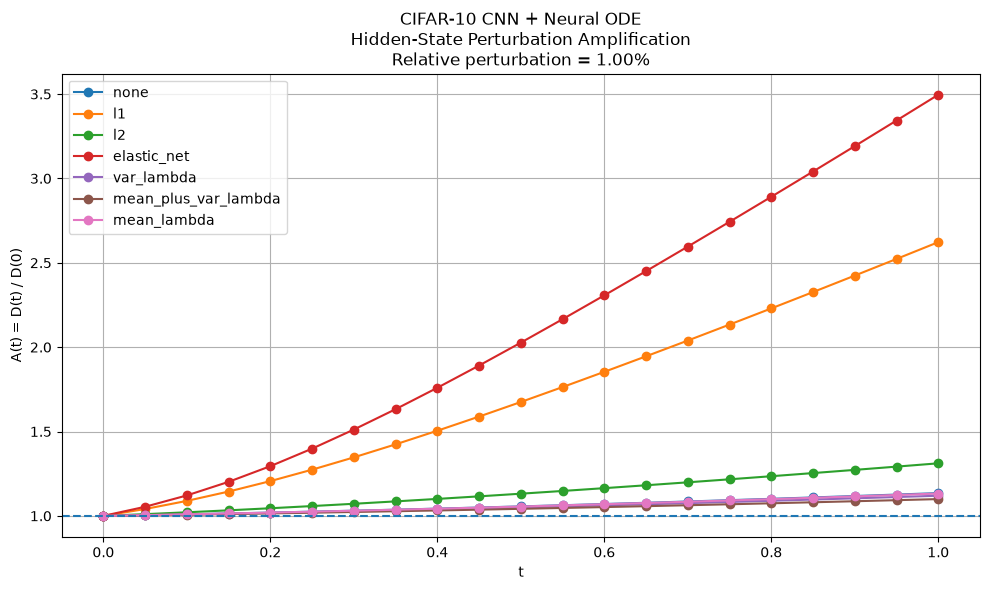

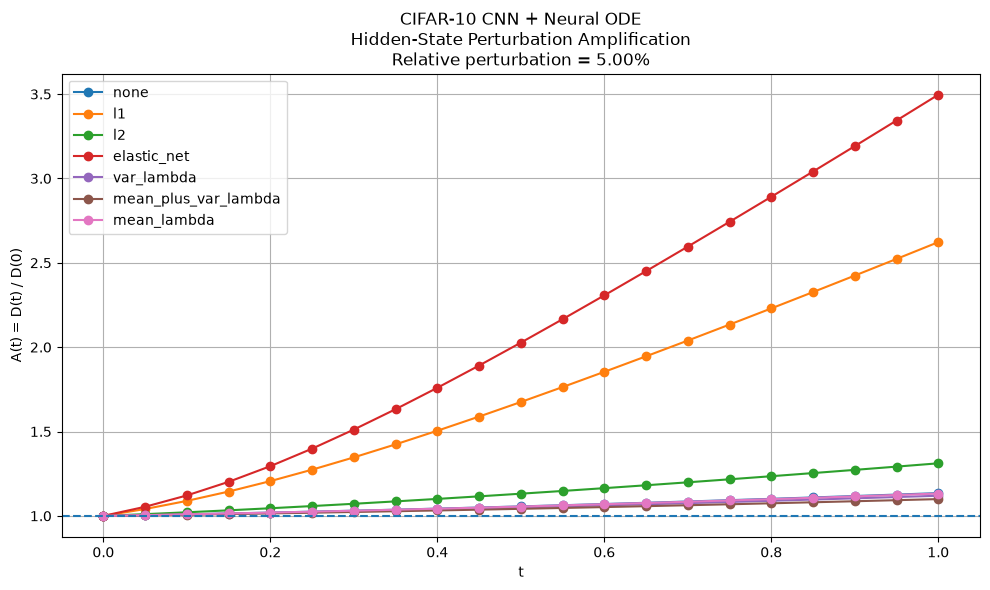

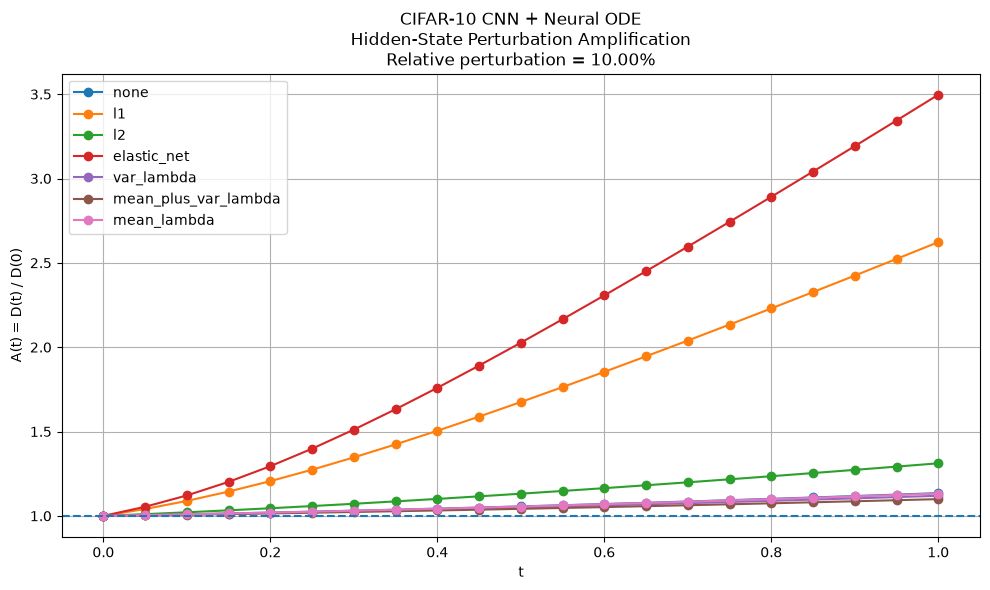

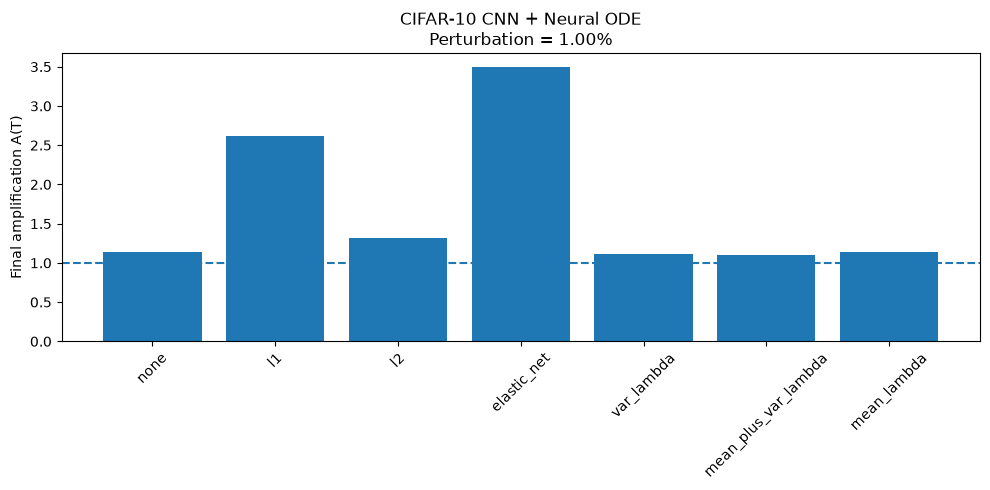

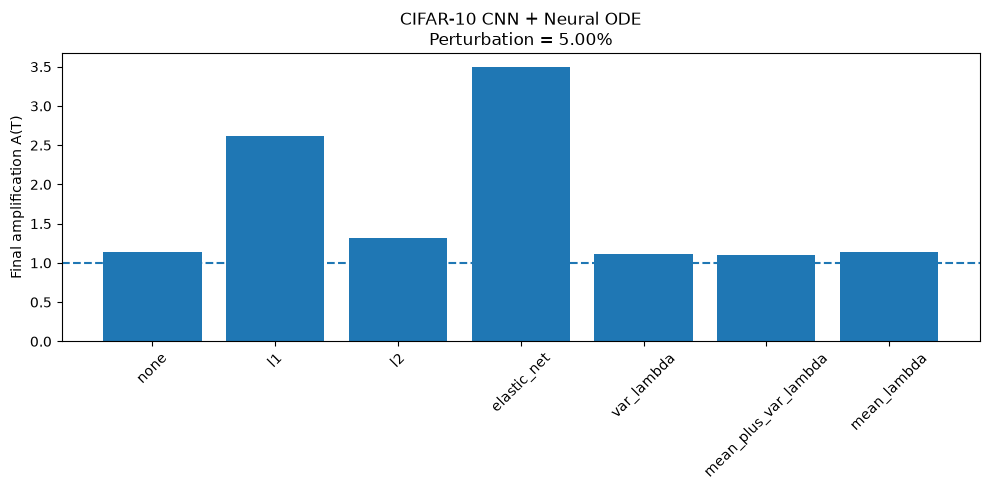

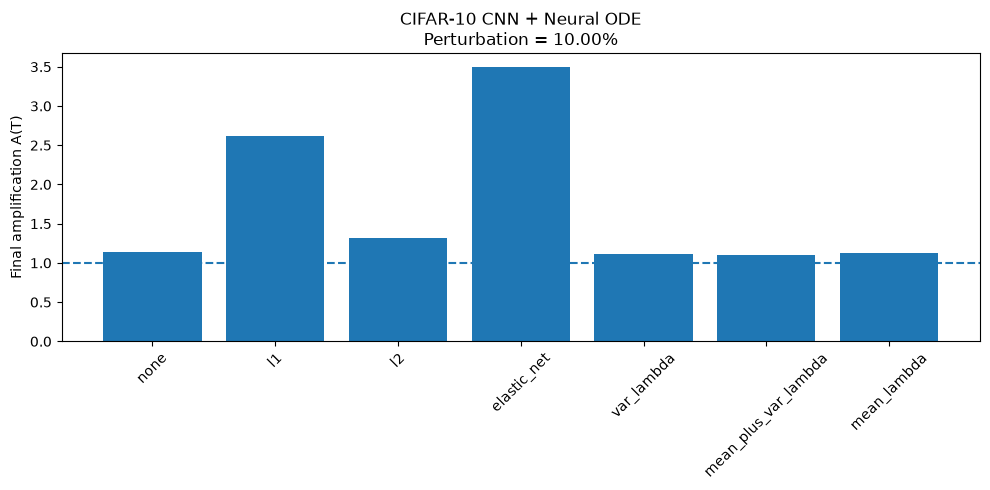

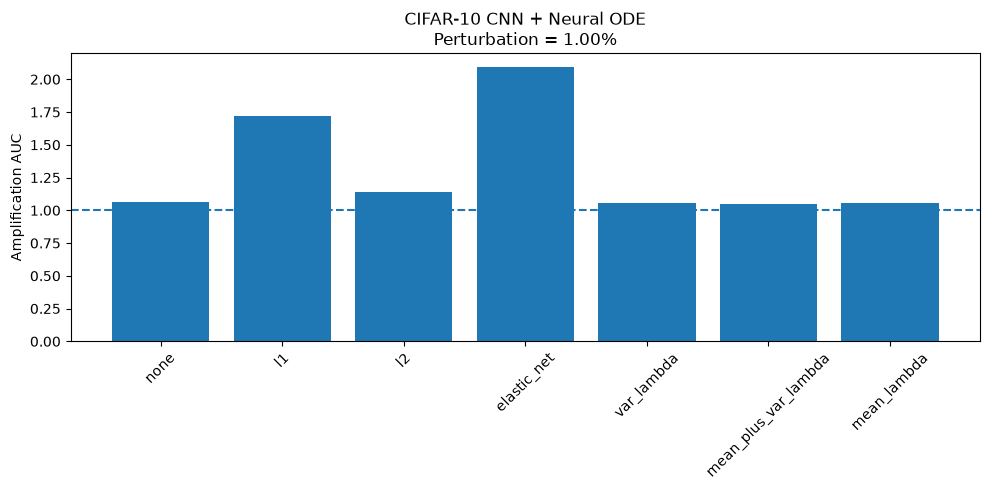

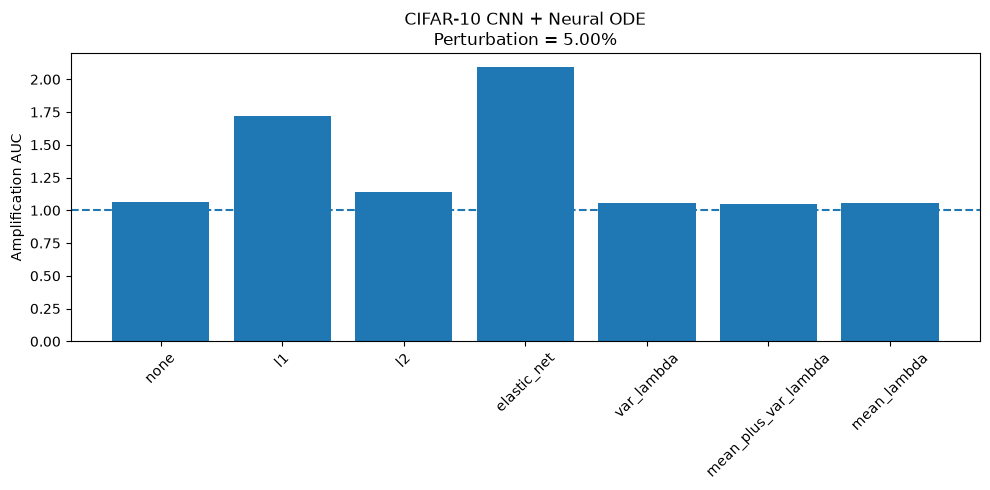

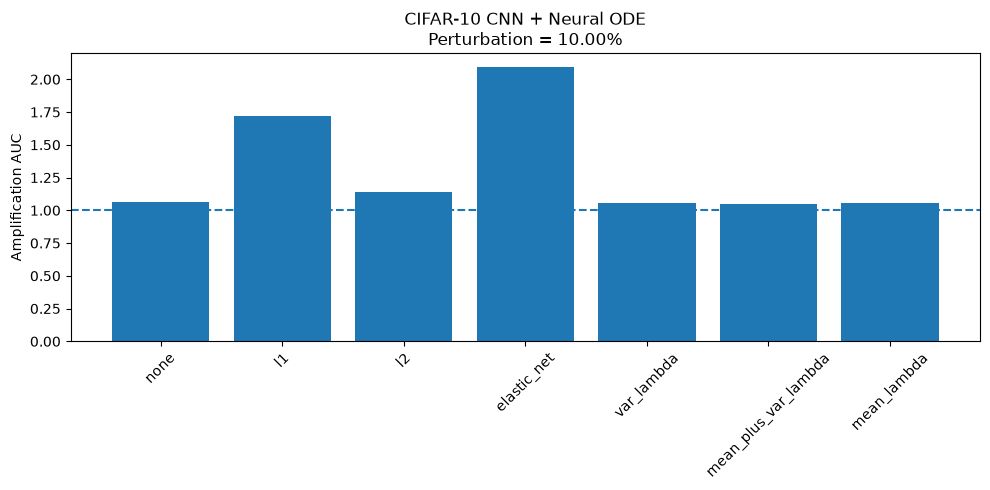


EXPERIMENT FINISHED

Dataset: CIFAR-10
Architecture: CNN Encoder + Neural ODE
Official training pool: 50000
Official test split: NOT USED
Train per seed: 37500
Validation per seed: 12500
Hidden dimension: 32
Neural ODE: 32 -> 64 -> 64 -> 32
Mini-batch size: 512
Optimizer updates: ONE PER MINI-BATCH
Batches per epoch: 74
Spectral regularization every N batches: 5
Approx spectral evaluations per epoch: 14
Spectral samples per evaluation: 8
RK4 step_size: 0.05
Post-training spectral samples: 512
Post-training spectral times: 10
Post-training var_lambda: global variance over samples x times
Variance decomposition: within-time + between-time
eigvalsh successful: 13171200
eigvals fallback: 0
Eigensolver fallback rate: 0.00000000%

Output prefix: 260926_cifar10_cnn_minibatch_v2


In [1]:
# ============================================================
# NEURAL ODE + CNN ENCODER - CIFAR-10
# Apple Silicon / MPS
#
# ============================================================
# PROTOCOLO V2 - EXTENSÃO CIFAR-10 / CNN
# + MINI-BATCH TRAINING
# + SPECTRAL REGULARIZATION EVERY N BATCHES
# ============================================================
#
# PIPELINE:
#
# CIFAR-10
#     ↓
# CNN Encoder
#     ↓
# h0 ∈ R^32
#     ↓
# Neural ODE
#     32 → 64 → 64 → 32
#     ↓
# Linear Decoder
#     ↓
# 10 classes
#
# ============================================================
# TREINAMENTO
# ============================================================
#
# optimizer.step() EM CADA MINI-BATCH.
#
# Para regularizadores espectrais:
#
#     var_lambda
#     mean_lambda
#     mean_plus_var_lambda
#
# a regularização espectral é calculada a cada:
#
#     spectral_every_n_batches = 5
#
# Nos demais batches:
#
#     loss = CE
#
# ============================================================
# CONFIGURAÇÃO
# ============================================================
#
# seeds = 1..30
# epochs = 300
# batch_size = 512
# hidden_dim = 32
# lr = 1e-3
#
# RK4 step_size = 0.05
#
# alpha_mean = 1e-4
# beta_var = 1e-3
#
# max_reg_samples = 8
#
# spectral_every_n_batches = 5
#
# L1 / L2 / ElasticNet = 1e-5
#
# Perturbações:
#     1%, 5%, 10%
#
# 10 direções por modelo
#
# Pós-treino:
#     512 validation samples
#     10 tempos
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import random
import gc

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt

from torchdiffeq import odeint

from torchvision.datasets import CIFAR10

from sklearn.model_selection import train_test_split


# ============================================================
# 1. DEVICE
# ============================================================

if torch.backends.mps.is_available():
    device = torch.device("mps")

elif torch.cuda.is_available():
    device = torch.device("cuda")

else:
    device = torch.device("cpu")


print("Device:", device)


# ============================================================
# 2. REPRODUTIBILIDADE
# ============================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ============================================================
# 3. CONFIGURAÇÃO EXPERIMENTAL
# ============================================================

dataset_type = "cifar10"

seeds = list(range(1, 31))

reg_types = [
    "none",
    "l1",
    "l2",
    "elastic_net",
    "var_lambda",
    "mean_plus_var_lambda",
    "mean_lambda",
]

epochs = 300

lr = 1e-3

hidden_dim = 32


# ============================================================
# MINI-BATCH
# ============================================================

train_batch_size = 512

validation_batch_size = 512

encoder_batch_size = 512


# ============================================================
# FREQUÊNCIA DA REGULARIZAÇÃO ESPECTRAL
# ============================================================

spectral_every_n_batches = 5


# ============================================================
# AVALIAÇÃO ESPECTRAL
# ============================================================

spectral_max_points = 512

spectral_time_points = 10


# ============================================================
# RK4
# ============================================================

RK4_STEP_SIZE = 0.05

RK4_OPTIONS = {
    "step_size": RK4_STEP_SIZE
}


# ============================================================
# 4. REGULARIZAÇÃO ESPECTRAL
# ============================================================

alpha_mean = 1e-4

beta_var = 1e-3

max_reg_samples = 8


# ============================================================
# 5. REGULARIZAÇÕES CLÁSSICAS
# ============================================================

lambda_l1 = 1e-5

lambda_l2 = 1e-5

lambda_elastic_l1 = 1e-5

lambda_elastic_l2 = 1e-5


# ============================================================
# 6. PERTURBAÇÕES
# ============================================================

hidden_perturbation_levels = [
    0.01,
    0.05,
    0.10,
]

n_perturbation_repeats = 10

stability_time_points = 21


# ============================================================
# 7. EIGENSOLVER STATS
# ============================================================

eigen_solver_stats = {
    "eigvalsh_success": 0,
    "eigvals_fallback": 0,
}


# ============================================================
# 8. CNN ENCODER
# ============================================================

class CNNEncoder(nn.Module):

    def __init__(
        self,
        hidden_dim=32
    ):

        super().__init__()

        self.features = nn.Sequential(

            # 3 x 32 x 32

            nn.Conv2d(
                3,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.Conv2d(
                64,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            # 64 x 16 x 16

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.Conv2d(
                128,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            # 128 x 8 x 8

            nn.Conv2d(
                128,
                256,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.AdaptiveAvgPool2d(
                (1, 1)
            ),

            nn.Flatten()
        )


        self.projection = nn.Linear(
            256,
            hidden_dim
        )


    def forward(
        self,
        x
    ):

        x = self.features(x)

        h0 = self.projection(x)

        return h0


# ============================================================
# 9. ODE FUNCTION
# ============================================================

class ODEFunc(nn.Module):

    def __init__(
        self,
        hidden_dim
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                hidden_dim,
                64
            ),

            nn.Tanh(),

            nn.Linear(
                64,
                64
            ),

            nn.Tanh(),

            nn.Linear(
                64,
                hidden_dim
            )
        )


    def forward(
        self,
        t,
        h
    ):

        return self.net(h)


# ============================================================
# 10. NEURAL ODE CLASSIFIER
# ============================================================

class NeuralODEClassifier(nn.Module):

    def __init__(
        self,
        hidden_dim=32,
        num_classes=10
    ):

        super().__init__()

        self.hidden_dim = hidden_dim

        self.encoder = CNNEncoder(
            hidden_dim=hidden_dim
        )

        self.odefunc = ODEFunc(
            hidden_dim
        )

        self.decoder = nn.Linear(
            hidden_dim,
            num_classes
        )


    def forward(
        self,
        x,
        return_traj=False
    ):

        h0 = self.encoder(x)

        t = torch.tensor(
            [0.0, 1.0],
            dtype=h0.dtype,
            device=h0.device
        )


        h_t = odeint(
            self.odefunc,
            h0,
            t,
            method="rk4",
            options=RK4_OPTIONS
        )


        h_final = h_t[-1]

        logits = self.decoder(
            h_final
        )


        if return_traj:

            return (
                logits,
                h_t
            )


        return logits


# ============================================================
# 11. JACOBIANO ANALÍTICO
#
# J = W3 D2 W2 D1 W1
# ============================================================

def analytical_jacobian(
    odefunc,
    h
):

    if h.dim() == 2:

        if h.shape[0] != 1:

            raise ValueError(
                "analytical_jacobian expects "
                "exactly one hidden state."
            )

        h = h.squeeze(0)


    if h.dim() != 1:

        raise ValueError(
            "analytical_jacobian expects "
            "a one-dimensional hidden state."
        )


    layer1 = odefunc.net[0]
    layer2 = odefunc.net[2]
    layer3 = odefunc.net[4]


    W1 = layer1.weight
    b1 = layer1.bias

    W2 = layer2.weight
    b2 = layer2.bias

    W3 = layer3.weight


    z1 = W1 @ h + b1

    a1 = torch.tanh(z1)


    z2 = W2 @ a1 + b2

    a2 = torch.tanh(z2)


    d1 = 1.0 - a1.pow(2)

    d2 = 1.0 - a2.pow(2)


    D1_W1 = (
        d1.unsqueeze(1)
        *
        W1
    )


    W2_D1_W1 = (
        W2
        @
        D1_W1
    )


    D2_W2_D1_W1 = (
        d2.unsqueeze(1)
        *
        W2_D1_W1
    )


    J = (
        W3
        @
        D2_W2_D1_W1
    )


    return J


# ============================================================
# 12. ROBUST LAMBDA MAX
# ============================================================

def robust_lambda_max_from_jacobian(J):

    global eigen_solver_stats


    if not torch.isfinite(J).all():

        raise RuntimeError(
            "Jacobian contains NaN or Inf."
        )


    if J.device.type == "mps":
        torch.mps.synchronize()


    J_cpu = (
        J
        .to(device="cpu")
        .to(dtype=torch.float64)
    )


    S_cpu = (
        0.5 * J_cpu
        +
        0.5 * J_cpu.T
    )


    S_cpu = (
        0.5 * S_cpu
        +
        0.5 * S_cpu.T
    )


    try:

        eigvals = torch.linalg.eigvalsh(
            S_cpu
        )


        eigen_solver_stats[
            "eigvalsh_success"
        ] += 1


        lambda_max_cpu = eigvals[-1]


    except RuntimeError as error:

        eigen_solver_stats[
            "eigvals_fallback"
        ] += 1


        print(
            "\nWarning: eigvalsh failed."
        )


        print(
            "Fallback eigvals."
        )


        print(
            "Original error:",
            str(error)
        )


        eigvals_general = torch.linalg.eigvals(
            S_cpu
        )


        lambda_max_cpu = (
            eigvals_general
            .real
            .max()
        )


    return (
        lambda_max_cpu
        .to(dtype=J.dtype)
        .to(device=J.device)
    )


# ============================================================
# 13. LAMBDA MAX DA PARTE SIMÉTRICA
# ============================================================

def lambda_max_symmetric(
    odefunc,
    h
):

    h = (
        h
        .detach()
        .clone()
    )


    J = analytical_jacobian(
        odefunc,
        h
    )


    return robust_lambda_max_from_jacobian(
        J
    )


# ============================================================
# 14. REGULARIZADOR ESPECTRAL
# ============================================================

def spectral_regularizer(
    model,
    x_batch,
    seed,
    epoch,
    batch_idx
):

    n = min(
        x_batch.shape[0],
        max_reg_samples
    )


    # ========================================================
    # Seleção determinística dos 8 exemplos.
    #
    # Mesmo seed + epoch + batch_idx produz a mesma seleção
    # entre var_lambda / mean_lambda / mean_plus_var_lambda.
    # ========================================================

    spectral_sampling_seed = (

        1_000_000
        +
        seed * 1_000_000
        +
        epoch * 1_000
        +
        batch_idx
    )


    rng = np.random.default_rng(
        spectral_sampling_seed
    )


    indices_np = rng.choice(
        x_batch.shape[0],
        size=n,
        replace=False
    )


    indices = torch.tensor(
        indices_np,
        dtype=torch.long,
        device=x_batch.device
    )


    x_reg = x_batch.index_select(
        0,
        indices
    )


    h0 = model.encoder(
        x_reg
    )


    t_eval = torch.linspace(
        0.0,
        1.0,
        4,
        dtype=h0.dtype,
        device=h0.device
    )


    h_traj = odeint(
        model.odefunc,
        h0,
        t_eval,
        method="rk4",
        options=RK4_OPTIONS
    )


    lambdas = []


    for k in range(
        len(t_eval)
    ):

        for i in range(n):

            h = h_traj[
                k,
                i
            ]


            lam = lambda_max_symmetric(
                model.odefunc,
                h
            )


            lambdas.append(
                lam
            )


    lambdas = torch.stack(
        lambdas
    )


    mean_lambda = lambdas.mean()


    var_lambda = lambdas.var(
        unbiased=False
    )


    return (
        mean_lambda,
        var_lambda,
        lambdas
    )


# ============================================================
# 15. ACCURACY EM BATCHES
# ============================================================

@torch.no_grad()
def evaluate_accuracy_batched(
    model,
    X_cpu,
    y_cpu,
    batch_size=512
):

    model.eval()


    correct = 0

    total = 0


    for start in range(
        0,
        len(X_cpu),
        batch_size
    ):


        end = min(
            start + batch_size,
            len(X_cpu)
        )


        xb = (
            X_cpu[start:end]
            .to(device)
        )


        yb = (
            y_cpu[start:end]
            .to(device)
        )


        logits = model(
            xb
        )


        pred = logits.argmax(
            dim=1
        )


        correct += (
            pred == yb
        ).sum().item()


        total += yb.numel()


        del xb
        del yb
        del logits
        del pred


    return (
        correct
        /
        total
    )


# ============================================================
# 16. ENCODE DATASET EM BATCHES
# ============================================================

@torch.no_grad()
def encode_dataset_in_batches(
    model,
    X_cpu,
    batch_size=512,
    output_device=None
):

    model.eval()


    if output_device is None:

        output_device = device


    hidden_list = []


    for start in range(
        0,
        len(X_cpu),
        batch_size
    ):


        end = min(
            start + batch_size,
            len(X_cpu)
        )


        xb = (
            X_cpu[start:end]
            .to(device)
        )


        hb = model.encoder(
            xb
        )


        hidden_list.append(
            hb.detach().to(
                output_device
            )
        )


        del xb
        del hb


    return torch.cat(
        hidden_list,
        dim=0
    )


# ============================================================
# 17. JACOBIAN METRICS CPU
# ============================================================

def jacobian_metrics_cpu(
    odefunc_cpu,
    h_batch_cpu,
    max_points=512
):

    odefunc_cpu.eval()


    h_batch_cpu = h_batch_cpu[
        :max_points
    ]


    frob_list = []

    frob_sq_list = []

    lambda_list = []


    for i in range(
        h_batch_cpu.shape[0]
    ):


        h = (
            h_batch_cpu[
                i:i+1
            ]
            .detach()
            .clone()
            .to(dtype=torch.float64)
        )


        J = analytical_jacobian(
            odefunc_cpu,
            h
        )


        frob = torch.norm(
            J,
            p="fro"
        )


        frob_sq = (
            frob ** 2
        )


        lambda_max = (
            robust_lambda_max_from_jacobian(
                J
            )
        )


        frob_list.append(
            frob
        )


        frob_sq_list.append(
            frob_sq
        )


        lambda_list.append(
            lambda_max
        )


    frob_tensor = torch.stack(
        frob_list
    )


    frob_sq_tensor = torch.stack(
        frob_sq_list
    )


    lambda_tensor = torch.stack(
        lambda_list
    )


    lambda_values = (
        lambda_tensor
        .detach()
        .cpu()
        .numpy()
        .astype(np.float64)
    )


    return {

        "frob_mean":
            frob_tensor.mean().item(),

        "frob_sq_mean":
            frob_sq_tensor.mean().item(),

        "lambda_mean":
            lambda_tensor.mean().item(),

        "lambda_var_within_time":
            lambda_tensor.var(
                unbiased=False
            ).item(),

        "lambda_max":
            lambda_tensor.max().item(),

        "lambda_values":
            lambda_values,
    }


# ============================================================
# 18. JACOBIAN TRAJECTORY
# ============================================================

def evaluate_jacobian_trajectory_cpu(
    model,
    X_val_cpu,
    max_points=512,
    n_time_points=10
):


    h0_cpu = (
        encode_dataset_in_batches(

            model=model,

            X_cpu=
                X_val_cpu[
                    :max_points
                ],

            batch_size=
                encoder_batch_size,

            output_device=
                torch.device("cpu")
        )

        .to(dtype=torch.float64)
    )


    odefunc_cpu = ODEFunc(
        hidden_dim
    )


    state_dict = {

        key:
            value
            .detach()
            .cpu()

        for key, value
        in model.odefunc.state_dict().items()
    }


    odefunc_cpu.load_state_dict(
        state_dict
    )


    odefunc_cpu = odefunc_cpu.to(
        device="cpu",
        dtype=torch.float64
    )


    t_eval_cpu = torch.linspace(
        0.0,
        1.0,
        n_time_points,
        dtype=torch.float64
    )


    with torch.no_grad():

        h_traj_cpu = odeint(
            odefunc_cpu,
            h0_cpu,
            t_eval_cpu,
            method="rk4",
            options=RK4_OPTIONS
        )


    trajectory_metrics = []


    for k in range(
        len(t_eval_cpu)
    ):

        metrics = jacobian_metrics_cpu(
            odefunc_cpu,
            h_traj_cpu[k],
            max_points=max_points
        )


        trajectory_metrics.append(
            metrics
        )


    del odefunc_cpu
    del state_dict
    del h0_cpu
    del h_traj_cpu

    gc.collect()


    return trajectory_metrics


# ============================================================
# 19. HIDDEN-STATE STABILITY
# ============================================================

@torch.no_grad()
def evaluate_hidden_state_stability_from_hidden(
    model,
    h0,
    y,
    relative_perturbation,
    t_eval,
    perturbation_seed,
    n_repeats=10
):

    model.eval()


    clean_traj = odeint(
        model.odefunc,
        h0,
        t_eval,
        method="rk4",
        options=RK4_OPTIONS
    )


    clean_final = clean_traj[-1]


    clean_logits = model.decoder(
        clean_final
    )


    clean_pred = clean_logits.argmax(
        dim=1
    )


    clean_accuracy = (
        clean_pred == y
    ).float().mean().item()


    distance_repeats = []

    amplification_repeats = []

    final_logit_changes = []

    prediction_flip_rates = []

    perturbed_accuracies = []


    for repeat in range(
        n_repeats
    ):


        rng = np.random.default_rng(
            perturbation_seed
            +
            repeat
        )


        random_direction_np = rng.normal(
            0.0,
            1.0,
            size=tuple(h0.shape)
        ).astype(
            np.float32
        )


        random_direction = torch.tensor(
            random_direction_np,
            dtype=h0.dtype,
            device=h0.device
        )


        direction_norm = torch.linalg.vector_norm(
            random_direction,
            ord=2,
            dim=1,
            keepdim=True
        )


        random_direction = (
            random_direction
            /
            (
                direction_norm
                +
                1e-12
            )
        )


        h0_norm = torch.linalg.vector_norm(
            h0,
            ord=2,
            dim=1,
            keepdim=True
        )


        perturbation_norm = (
            relative_perturbation
            *
            torch.clamp(
                h0_norm,
                min=1e-8
            )
        )


        delta_h0 = (
            random_direction
            *
            perturbation_norm
        )


        h0_perturbed = (
            h0
            +
            delta_h0
        )


        perturbed_traj = odeint(
            model.odefunc,
            h0_perturbed,
            t_eval,
            method="rk4",
            options=RK4_OPTIONS
        )


        distance = torch.linalg.vector_norm(
            perturbed_traj
            -
            clean_traj,
            ord=2,
            dim=2
        )


        initial_distance = torch.linalg.vector_norm(
            delta_h0,
            ord=2,
            dim=1
        )


        amplification = (
            distance
            /
            (
                initial_distance.unsqueeze(0)
                +
                1e-12
            )
        )


        distance_repeats.append(
            distance
        )


        amplification_repeats.append(
            amplification
        )


        perturbed_final = (
            perturbed_traj[-1]
        )


        perturbed_logits = model.decoder(
            perturbed_final
        )


        perturbed_pred = perturbed_logits.argmax(
            dim=1
        )


        perturbed_accuracy = (
            perturbed_pred
            ==
            y
        ).float().mean()


        prediction_flip_rate = (
            perturbed_pred
            !=
            clean_pred
        ).float().mean()


        logit_change = torch.linalg.vector_norm(
            perturbed_logits
            -
            clean_logits,
            ord=2,
            dim=1
        )


        final_logit_changes.append(
            logit_change
        )


        prediction_flip_rates.append(
            prediction_flip_rate
        )


        perturbed_accuracies.append(
            perturbed_accuracy
        )


    distances = torch.stack(
        distance_repeats,
        dim=0
    )


    amplifications = torch.stack(
        amplification_repeats,
        dim=0
    )


    final_logit_changes = torch.stack(
        final_logit_changes,
        dim=0
    )


    prediction_flip_rates = torch.stack(
        prediction_flip_rates
    )


    perturbed_accuracies = torch.stack(
        perturbed_accuracies
    )


    distance_curve_mean = distances.mean(
        dim=(0, 2)
    )


    distance_curve_std = distances.std(
        dim=(0, 2),
        unbiased=False
    )


    amplification_curve_mean = amplifications.mean(
        dim=(0, 2)
    )


    amplification_curve_std = amplifications.std(
        dim=(0, 2),
        unbiased=False
    )


    final_amplification = amplifications[
        :,
        -1,
        :
    ]


    final_amplification_mean = (
        final_amplification
        .mean()
        .item()
    )


    final_amplification_std = (
        final_amplification
        .std(
            unbiased=False
        )
        .item()
    )


    final_distance = distances[
        :,
        -1,
        :
    ]


    final_distance_mean = (
        final_distance
        .mean()
        .item()
    )


    max_amplification_mean = (
        amplifications
        .max(dim=1)
        .values
        .mean()
        .item()
    )


    dt = (
        t_eval[1:]
        -
        t_eval[:-1]
    )


    trapezoids = (
        0.5
        *
        (
            amplifications[:, :-1, :]
            +
            amplifications[:, 1:, :]
        )
        *
        dt.view(
            1,
            -1,
            1
        )
    )


    amplification_auc = (
        trapezoids.sum(
            dim=1
        )
        /
        (
            t_eval[-1]
            -
            t_eval[0]
        )
    )


    amplification_auc_mean = (
        amplification_auc
        .mean()
        .item()
    )


    fraction_final_contracted = (
        final_amplification
        <
        1.0
    ).float().mean().item()


    log_final_amplification_mean = (
        torch.log(
            final_amplification
            +
            1e-12
        )
        .mean()
        .item()
    )


    return {

        "clean_accuracy":
            clean_accuracy,

        "perturbed_accuracy":
            perturbed_accuracies.mean().item(),

        "prediction_flip_rate":
            prediction_flip_rates.mean().item(),

        "initial_distance_mean":
            distances[:, 0, :].mean().item(),

        "final_distance_mean":
            final_distance_mean,

        "final_amplification_mean":
            final_amplification_mean,

        "final_amplification_std":
            final_amplification_std,

        "max_amplification_mean":
            max_amplification_mean,

        "amplification_auc_mean":
            amplification_auc_mean,

        "fraction_final_contracted":
            fraction_final_contracted,

        "log_final_amplification_mean":
            log_final_amplification_mean,

        "final_logit_change_mean":
            final_logit_changes.mean().item(),

        "distance_curve_mean":
            distance_curve_mean.cpu().numpy(),

        "distance_curve_std":
            distance_curve_std.cpu().numpy(),

        "amplification_curve_mean":
            amplification_curve_mean.cpu().numpy(),

        "amplification_curve_std":
            amplification_curve_std.cpu().numpy(),
    }


# ============================================================
# 20. LOAD CIFAR-10
# ============================================================

print(
    "\n"
    +
    "=" * 120
)


print(
    "LOADING CIFAR-10"
)


print(
    "=" * 120
)


cifar10 = CIFAR10(
    root="./data",
    train=True,
    download=True
)


X_raw = (
    cifar10.data
    .transpose(
        0,
        3,
        1,
        2
    )
)


y_raw = np.asarray(
    cifar10.targets,
    dtype=np.int64
)


print(
    "X:",
    X_raw.shape
)


print(
    "y:",
    y_raw.shape
)


print(
    "Class distribution:"
)


print(
    np.unique(
        y_raw,
        return_counts=True
    )
)


assert X_raw.shape == (
    50000,
    3,
    32,
    32
)


assert y_raw.min() == 0

assert y_raw.max() == 9


num_classes = 10


# ============================================================
# 21. DATA PREPARATION PER SEED
# ============================================================

def prepare_data_for_seed(
    seed
):


    indices = np.arange(
        len(y_raw)
    )


    (
        train_indices,
        val_indices

    ) = train_test_split(

        indices,

        test_size=0.25,

        stratify=y_raw,

        random_state=seed
    )


    X_train_np = (
        X_raw[
            train_indices
        ]
        .astype(np.float32)
        /
        255.0
    )


    X_val_np = (
        X_raw[
            val_indices
        ]
        .astype(np.float32)
        /
        255.0
    )


    y_train_np = y_raw[
        train_indices
    ]


    y_val_np = y_raw[
        val_indices
    ]


    # ========================================================
    # Normalização por canal
    #
    # Estatísticas calculadas APENAS no training split.
    # ========================================================

    channel_mean = X_train_np.mean(
        axis=(0, 2, 3),
        keepdims=True
    )


    channel_std = X_train_np.std(
        axis=(0, 2, 3),
        keepdims=True
    )


    channel_std = np.maximum(
        channel_std,
        1e-8
    )


    X_train_np = (
        X_train_np
        -
        channel_mean
    ) / channel_std


    X_val_np = (
        X_val_np
        -
        channel_mean
    ) / channel_std


    X_train = torch.from_numpy(
        X_train_np
    ).float()


    X_val = torch.from_numpy(
        X_val_np
    ).float()


    y_train = torch.from_numpy(
        y_train_np
    ).long()


    y_val = torch.from_numpy(
        y_val_np
    ).long()


    del X_train_np
    del X_val_np


    gc.collect()


    return (
        X_train,
        y_train,
        X_val,
        y_val
    )


# ============================================================
# 22. RESULT CONTAINERS
# ============================================================

model_results_all = []

stability_seed_results_all = []

stability_trajectory_results_all = []


# ============================================================
# 23. MAIN LOOP
# ============================================================

for reg_type in reg_types:


    print(
        "\n"
        +
        "=" * 120
    )


    print(
        f"REGULARIZER: {reg_type}"
    )


    print(
        "=" * 120
    )


    for seed in seeds:


        print(
            f"\n>>> INICIANDO "
            f"reg={reg_type} | "
            f"seed={seed} <<<"
        )


        set_seed(
            seed
        )


        (
            X_train_cpu,
            y_train_cpu,
            X_val_cpu,
            y_val_cpu

        ) = prepare_data_for_seed(
            seed
        )


        n_train = len(
            X_train_cpu
        )


        n_val = len(
            X_val_cpu
        )


        n_batches = int(
            np.ceil(
                n_train
                /
                train_batch_size
            )
        )


        print(
            f"Train size={n_train} | "
            f"Val size={n_val} | "
            f"Batches/epoch={n_batches} | "
            f"Spectral every={spectral_every_n_batches}"
        )


        model = NeuralODEClassifier(
            hidden_dim=hidden_dim,
            num_classes=num_classes
        ).to(
            device
        )


        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=lr
        )


        # ====================================================
        # TRAINING
        # ====================================================

        for epoch in range(
            1,
            epochs + 1
        ):


            model.train()


            # =================================================
            # Deterministic permutation:
            #
            # mesma seed/epoch => mesmos minibatches
            # entre regularizadores.
            # =================================================

            permutation_generator = torch.Generator(
                device="cpu"
            )


            permutation_generator.manual_seed(

                2_000_000
                +
                seed * 10_000
                +
                epoch
            )


            permutation = torch.randperm(
                n_train,
                generator=
                    permutation_generator
            )


            epoch_ce_sum = 0.0

            epoch_loss_sum = 0.0

            spectral_mean_values = []

            spectral_var_values = []

            spectral_update_count = 0


            # =================================================
            # MINI-BATCH LOOP
            # =================================================

            for batch_idx, start in enumerate(

                range(
                    0,
                    n_train,
                    train_batch_size
                ),

                start=1
            ):


                end = min(
                    start
                    +
                    train_batch_size,
                    n_train
                )


                batch_indices = permutation[
                    start:end
                ]


                xb = (
                    X_train_cpu[
                        batch_indices
                    ]
                    .to(device)
                )


                yb = (
                    y_train_cpu[
                        batch_indices
                    ]
                    .to(device)
                )


                # =============================================
                # ONE OPTIMIZATION UPDATE PER MINI-BATCH
                # =============================================

                optimizer.zero_grad(
                    set_to_none=True
                )


                logits = model(
                    xb
                )


                ce = F.cross_entropy(
                    logits,
                    yb
                )


                # =============================================
                # DEFAULT REGULARIZATION
                # =============================================

                regularization = torch.tensor(
                    0.0,
                    dtype=ce.dtype,
                    device=device
                )


                mean_lam_batch = torch.tensor(
                    0.0,
                    dtype=ce.dtype,
                    device=device
                )


                var_lam_batch = torch.tensor(
                    0.0,
                    dtype=ce.dtype,
                    device=device
                )


                # =============================================
                # NONE
                # =============================================

                if reg_type == "none":

                    pass


                # =============================================
                # L1
                # =============================================

                elif reg_type == "l1":


                    l1_penalty = torch.tensor(
                        0.0,
                        device=device
                    )


                    for p in model.parameters():

                        l1_penalty = (
                            l1_penalty
                            +
                            p.abs().sum()
                        )


                    regularization = (
                        lambda_l1
                        *
                        l1_penalty
                    )


                # =============================================
                # L2
                # =============================================

                elif reg_type == "l2":


                    l2_penalty = torch.tensor(
                        0.0,
                        device=device
                    )


                    for p in model.parameters():

                        l2_penalty = (
                            l2_penalty
                            +
                            (
                                p ** 2
                            ).sum()
                        )


                    regularization = (
                        lambda_l2
                        *
                        l2_penalty
                    )


                # =============================================
                # ELASTIC NET
                # =============================================

                elif reg_type == "elastic_net":


                    l1_penalty = torch.tensor(
                        0.0,
                        device=device
                    )


                    l2_penalty = torch.tensor(
                        0.0,
                        device=device
                    )


                    for p in model.parameters():


                        l1_penalty = (
                            l1_penalty
                            +
                            p.abs().sum()
                        )


                        l2_penalty = (
                            l2_penalty
                            +
                            (
                                p ** 2
                            ).sum()
                        )


                    regularization = (

                        lambda_elastic_l1
                        *
                        l1_penalty

                        +

                        lambda_elastic_l2
                        *
                        l2_penalty
                    )


                # =============================================
                # SPECTRAL REGULARIZERS
                # =============================================

                elif reg_type in [

                    "var_lambda",

                    "mean_plus_var_lambda",

                    "mean_lambda"

                ]:


                    # =========================================
                    # spectral_every_n_batches = 5
                    #
                    # batches:
                    #
                    # 5, 10, 15, 20, ...
                    # =========================================

                    perform_spectral = (

                        batch_idx
                        %
                        spectral_every_n_batches
                        ==
                        0
                    )


                    if perform_spectral:


                        (
                            mean_lam_batch,
                            var_lam_batch,
                            _

                        ) = spectral_regularizer(

                            model=model,

                            x_batch=xb,

                            seed=seed,

                            epoch=epoch,

                            batch_idx=
                                batch_idx
                        )


                        spectral_mean_values.append(

                            mean_lam_batch
                            .detach()
                            .item()
                        )


                        spectral_var_values.append(

                            var_lam_batch
                            .detach()
                            .item()
                        )


                        spectral_update_count += 1


                        # =====================================
                        # VAR LAMBDA
                        # =====================================

                        if reg_type == "var_lambda":

                            regularization = (

                                beta_var

                                *

                                var_lam_batch
                            )


                        # =====================================
                        # MEAN + VAR
                        # =====================================

                        elif reg_type == (
                            "mean_plus_var_lambda"
                        ):


                            mean_penalty = F.softplus(
                                mean_lam_batch
                            )


                            regularization = (

                                alpha_mean
                                *
                                mean_penalty

                                +

                                beta_var
                                *
                                var_lam_batch
                            )


                        # =====================================
                        # MEAN
                        # =====================================

                        elif reg_type == "mean_lambda":


                            mean_penalty = F.softplus(
                                mean_lam_batch
                            )


                            regularization = (

                                alpha_mean

                                *

                                mean_penalty
                            )


                else:

                    raise ValueError(

                        f"Unknown regularizer: "
                        f"{reg_type}"
                    )


                # =============================================
                # TOTAL LOSS
                # =============================================

                loss = (
                    ce
                    +
                    regularization
                )


                if not torch.isfinite(
                    loss
                ).item():

                    raise RuntimeError(

                        f"Non-finite loss | "

                        f"reg={reg_type} | "

                        f"seed={seed} | "

                        f"epoch={epoch} | "

                        f"batch={batch_idx}"
                    )


                # =============================================
                # BACKPROPAGATION
                # =============================================

                loss.backward()


                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    1.0
                )


                # =============================================
                # UPDATE
                # =============================================

                optimizer.step()


                epoch_ce_sum += (
                    ce.detach().item()
                    *
                    len(yb)
                )


                epoch_loss_sum += (
                    loss.detach().item()
                    *
                    len(yb)
                )


                del xb
                del yb
                del logits
                del ce
                del loss
                del regularization


            # =================================================
            # EPOCH AVERAGES
            # =================================================

            epoch_ce = (
                epoch_ce_sum
                /
                n_train
            )


            epoch_loss = (
                epoch_loss_sum
                /
                n_train
            )


            if spectral_update_count > 0:

                epoch_mean_lambda = float(
                    np.mean(
                        spectral_mean_values
                    )
                )


                epoch_var_lambda = float(
                    np.mean(
                        spectral_var_values
                    )
                )


            else:

                epoch_mean_lambda = 0.0

                epoch_var_lambda = 0.0


            # =================================================
            # MONITORING
            # =================================================

            if epoch % 25 == 0:


                val_acc_epoch = evaluate_accuracy_batched(

                    model,

                    X_val_cpu,

                    y_val_cpu,

                    batch_size=
                        validation_batch_size
                )


                print(

                    f"reg={reg_type:20s} | "

                    f"seed={seed:02d} | "

                    f"epoch={epoch:03d} | "

                    f"loss={epoch_loss:.4f} | "

                    f"ce={epoch_ce:.4f} | "

                    f"val_acc="
                    f"{val_acc_epoch:.4f} | "

                    f"mean_lambda="
                    f"{epoch_mean_lambda:+.4f} | "

                    f"var_lambda="
                    f"{epoch_var_lambda:.6f} | "

                    f"spectral_updates="
                    f"{spectral_update_count}"
                )


            if device.type == "mps":

                try:
                    torch.mps.empty_cache()

                except Exception:
                    pass


        # ====================================================
        # 24. FINAL VALIDATION
        # ====================================================

        val_acc = evaluate_accuracy_batched(

            model,

            X_val_cpu,

            y_val_cpu,

            batch_size=
                validation_batch_size
        )


        print(

            f"\nFinal validation | "
            f"reg={reg_type} | "
            f"seed={seed} | "
            f"acc={val_acc:.6f}"
        )


        # ====================================================
        # 25. POST-TRAINING JACOBIAN TRAJECTORY
        # ====================================================

        print(

            "\nCalculando Jacobiano analítico "
            "em CPU/float64 | "

            f"reg={reg_type} | "
            f"seed={seed}"
        )


        trajectory_metrics = (

            evaluate_jacobian_trajectory_cpu(

                model=model,

                X_val_cpu=
                    X_val_cpu,

                max_points=
                    spectral_max_points,

                n_time_points=
                    spectral_time_points
            )
        )


        all_lambda_values = np.concatenate(

            [
                m[
                    "lambda_values"
                ]

                for m
                in trajectory_metrics
            ],

            axis=0
        )


        # ====================================================
        # GLOBAL MEAN
        # ====================================================

        mean_lambda_model = float(

            np.mean(
                all_lambda_values
            )
        )


        # ====================================================
        # GLOBAL VARIANCE
        # ====================================================

        var_lambda_model = float(

            np.var(
                all_lambda_values,
                ddof=0
            )
        )


        # ====================================================
        # WITHIN-TIME VARIANCE
        # ====================================================

        var_lambda_within_time_model = float(

            np.mean(

                [
                    m[
                        "lambda_var_within_time"
                    ]

                    for m
                    in trajectory_metrics
                ]
            )
        )


        # ====================================================
        # BETWEEN-TIME VARIANCE
        # ====================================================

        lambda_time_means = np.asarray(

            [
                m[
                    "lambda_mean"
                ]

                for m
                in trajectory_metrics
            ],

            dtype=np.float64
        )


        var_lambda_between_time_model = float(

            np.var(
                lambda_time_means,
                ddof=0
            )
        )


        variance_decomposition_sum = (

            var_lambda_within_time_model

            +

            var_lambda_between_time_model
        )


        variance_decomposition_error = float(

            abs(
                var_lambda_model
                -
                variance_decomposition_sum
            )
        )


        if variance_decomposition_error > 1e-10:

            raise RuntimeError(

                "Variance decomposition failed | "

                f"reg={reg_type} | "
                f"seed={seed} | "

                f"error="
                f"{variance_decomposition_error:.12e}"
            )


        max_lambda_model = float(

            np.max(
                all_lambda_values
            )
        )


        frobenius_model = float(

            np.mean(

                [
                    m[
                        "frob_mean"
                    ]

                    for m
                    in trajectory_metrics
                ]
            )
        )


        frobenius_sq_model = float(

            np.mean(

                [
                    m[
                        "frob_sq_mean"
                    ]

                    for m
                    in trajectory_metrics
                ]
            )
        )


        print(

            "\nSpectral variance decomposition | "

            f"global="
            f"{var_lambda_model:.6f} | "

            f"within="
            f"{var_lambda_within_time_model:.6f} | "

            f"between="
            f"{var_lambda_between_time_model:.6f} | "

            f"error="
            f"{variance_decomposition_error:.3e}"
        )


        # ====================================================
        # MODEL RESULTS
        # ====================================================

        model_results_all.append({

            "dataset":
                dataset_type,

            "reg_type":
                reg_type,

            "seed":
                seed,

            "val_acc":
                val_acc,

            "mean_lambda":
                mean_lambda_model,

            "var_lambda":
                var_lambda_model,

            "var_lambda_within_time":
                var_lambda_within_time_model,

            "var_lambda_between_time":
                var_lambda_between_time_model,

            "variance_decomposition_error":
                variance_decomposition_error,

            "max_lambda":
                max_lambda_model,

            "frobenius":
                frobenius_model,

            "frobenius_sq":
                frobenius_sq_model,
        })


        # ====================================================
        # 26. ENCODE VALIDATION DATA
        # ====================================================

        print(
            "\nEncoding validation set "
            "for hidden-state stability..."
        )


        h0_val = encode_dataset_in_batches(

            model,

            X_val_cpu,

            batch_size=
                encoder_batch_size,

            output_device=
                device
        )


        y_val_device = (
            y_val_cpu.to(
                device
            )
        )


        # ====================================================
        # 27. HIDDEN-STATE STABILITY
        # ====================================================

        stability_t_eval = torch.linspace(

            0.0,

            1.0,

            stability_time_points,

            dtype=torch.float32,

            device=device
        )


        for relative_perturbation in (
            hidden_perturbation_levels
        ):


            perturbation_seed = (

                500000

                +

                seed * 1000
            )


            stability = (

                evaluate_hidden_state_stability_from_hidden(

                    model=model,

                    h0=h0_val,

                    y=y_val_device,

                    relative_perturbation=
                        relative_perturbation,

                    t_eval=
                        stability_t_eval,

                    perturbation_seed=
                        perturbation_seed,

                    n_repeats=
                        n_perturbation_repeats
                )
            )


            stability_seed_results_all.append({

                "dataset":
                    dataset_type,

                "reg_type":
                    reg_type,

                "seed":
                    seed,

                "relative_perturbation":
                    relative_perturbation,

                "clean_accuracy":
                    stability[
                        "clean_accuracy"
                    ],

                "perturbed_accuracy":
                    stability[
                        "perturbed_accuracy"
                    ],

                "prediction_flip_rate":
                    stability[
                        "prediction_flip_rate"
                    ],

                "initial_distance_mean":
                    stability[
                        "initial_distance_mean"
                    ],

                "final_distance_mean":
                    stability[
                        "final_distance_mean"
                    ],

                "final_amplification_mean":
                    stability[
                        "final_amplification_mean"
                    ],

                "final_amplification_std":
                    stability[
                        "final_amplification_std"
                    ],

                "max_amplification_mean":
                    stability[
                        "max_amplification_mean"
                    ],

                "amplification_auc_mean":
                    stability[
                        "amplification_auc_mean"
                    ],

                "fraction_final_contracted":
                    stability[
                        "fraction_final_contracted"
                    ],

                "log_final_amplification_mean":
                    stability[
                        "log_final_amplification_mean"
                    ],

                "final_logit_change_mean":
                    stability[
                        "final_logit_change_mean"
                    ],

                "mean_lambda":
                    mean_lambda_model,

                "var_lambda":
                    var_lambda_model,

                "var_lambda_within_time":
                    var_lambda_within_time_model,

                "var_lambda_between_time":
                    var_lambda_between_time_model,

                "variance_decomposition_error":
                    variance_decomposition_error,

                "max_lambda":
                    max_lambda_model,

                "frobenius":
                    frobenius_model,

                "frobenius_sq":
                    frobenius_sq_model,
            })


            times_np = (
                stability_t_eval
                .detach()
                .cpu()
                .numpy()
            )


            for time_idx in range(
                len(times_np)
            ):


                stability_trajectory_results_all.append({

                    "dataset":
                        dataset_type,

                    "reg_type":
                        reg_type,

                    "seed":
                        seed,

                    "relative_perturbation":
                        relative_perturbation,

                    "time":
                        times_np[
                            time_idx
                        ],

                    "distance_mean":
                        stability[
                            "distance_curve_mean"
                        ][time_idx],

                    "distance_std":
                        stability[
                            "distance_curve_std"
                        ][time_idx],

                    "amplification_mean":
                        stability[
                            "amplification_curve_mean"
                        ][time_idx],

                    "amplification_std":
                        stability[
                            "amplification_curve_std"
                        ][time_idx],
                })


        # ====================================================
        # EIGENSOLVER STATUS
        # ====================================================

        total_eig_calls = (

            eigen_solver_stats[
                "eigvalsh_success"
            ]

            +

            eigen_solver_stats[
                "eigvals_fallback"
            ]
        )


        if total_eig_calls > 0:

            fallback_rate = (

                eigen_solver_stats[
                    "eigvals_fallback"
                ]

                /

                total_eig_calls

                *

                100.0
            )


            print(

                "\nEigensolver | "

                f"eigvalsh="
                f"{eigen_solver_stats['eigvalsh_success']} | "

                f"fallback="
                f"{eigen_solver_stats['eigvals_fallback']} | "

                f"rate="
                f"{fallback_rate:.8f}%"
            )


        # ====================================================
        # CLEANUP
        # ====================================================

        del model

        del X_train_cpu
        del y_train_cpu

        del X_val_cpu
        del y_val_cpu

        del h0_val
        del y_val_device


        gc.collect()


        if device.type == "mps":

            try:
                torch.mps.empty_cache()

            except Exception:
                pass


# ============================================================
# 28. DATAFRAMES
# ============================================================

model_results_df = pd.DataFrame(
    model_results_all
)


stability_seed_df = pd.DataFrame(
    stability_seed_results_all
)


stability_trajectory_df = pd.DataFrame(
    stability_trajectory_results_all
)


# ============================================================
# 29. MODEL SUMMARY
# ============================================================

model_summary_df = (

    model_results_df

    .groupby(
        "reg_type"
    )

    .agg(

        val_acc_mean=(
            "val_acc",
            "mean"
        ),

        val_acc_std=(
            "val_acc",
            "std"
        ),

        mean_lambda=(
            "mean_lambda",
            "mean"
        ),

        var_lambda=(
            "var_lambda",
            "mean"
        ),

        var_lambda_within_time=(
            "var_lambda_within_time",
            "mean"
        ),

        var_lambda_between_time=(
            "var_lambda_between_time",
            "mean"
        ),

        variance_decomposition_error_max=(
            "variance_decomposition_error",
            "max"
        ),

        max_lambda=(
            "max_lambda",
            "mean"
        ),

        frobenius=(
            "frobenius",
            "mean"
        ),

        frobenius_sq=(
            "frobenius_sq",
            "mean"
        )
    )

    .reset_index()
)


# ============================================================
# 30. STABILITY SUMMARY
# ============================================================

stability_summary_df = (

    stability_seed_df

    .groupby(
        [
            "reg_type",
            "relative_perturbation"
        ]
    )

    .agg(

        clean_accuracy_mean=(
            "clean_accuracy",
            "mean"
        ),

        perturbed_accuracy_mean=(
            "perturbed_accuracy",
            "mean"
        ),

        prediction_flip_rate_mean=(
            "prediction_flip_rate",
            "mean"
        ),

        initial_distance_mean=(
            "initial_distance_mean",
            "mean"
        ),

        final_distance_mean=(
            "final_distance_mean",
            "mean"
        ),

        final_amplification_mean=(
            "final_amplification_mean",
            "mean"
        ),

        final_amplification_std_across_seeds=(
            "final_amplification_mean",
            "std"
        ),

        max_amplification_mean=(
            "max_amplification_mean",
            "mean"
        ),

        amplification_auc_mean=(
            "amplification_auc_mean",
            "mean"
        ),

        fraction_final_contracted_mean=(
            "fraction_final_contracted",
            "mean"
        ),

        log_final_amplification_mean=(
            "log_final_amplification_mean",
            "mean"
        ),

        final_logit_change_mean=(
            "final_logit_change_mean",
            "mean"
        )
    )

    .reset_index()
)


# ============================================================
# 31. TRAJECTORY SUMMARY
# ============================================================

trajectory_summary_df = (

    stability_trajectory_df

    .groupby(
        [
            "reg_type",
            "relative_perturbation",
            "time"
        ]
    )

    .agg(

        distance_mean=(
            "distance_mean",
            "mean"
        ),

        distance_between_seed_std=(
            "distance_mean",
            "std"
        ),

        amplification_mean=(
            "amplification_mean",
            "mean"
        ),

        amplification_between_seed_std=(
            "amplification_mean",
            "std"
        )
    )

    .reset_index()
)


# ============================================================
# 32. PRINT SUMMARIES
# ============================================================

print(
    "\n"
    +
    "=" * 120
)


print(
    "MODEL SUMMARY - CIFAR-10 CNN + NEURAL ODE"
)


print(
    "=" * 120
)


print(
    model_summary_df.to_string(
        index=False
    )
)


print(
    "\n"
    +
    "=" * 120
)


print(
    "HIDDEN-STATE STABILITY SUMMARY - CIFAR-10"
)


print(
    "=" * 120
)


columns_to_show = [

    "reg_type",

    "relative_perturbation",

    "final_amplification_mean",

    "max_amplification_mean",

    "amplification_auc_mean",

    "fraction_final_contracted_mean",

    "prediction_flip_rate_mean",

    "perturbed_accuracy_mean",

    "final_logit_change_mean",
]


print(
    stability_summary_df[
        columns_to_show
    ].to_string(
        index=False
    )
)


# ============================================================
# 33. SAVE CSVs
# ============================================================

output_prefix = (
    "260926_cifar10_cnn_minibatch_v2"
)


model_results_df.to_csv(
    f"{output_prefix}_hidden_stability_model_seed_results.csv",
    index=False
)


model_summary_df.to_csv(
    f"{output_prefix}_hidden_stability_model_summary.csv",
    index=False
)


stability_seed_df.to_csv(
    f"{output_prefix}_hidden_stability_seed_results.csv",
    index=False
)


stability_summary_df.to_csv(
    f"{output_prefix}_hidden_stability_summary.csv",
    index=False
)


stability_trajectory_df.to_csv(
    f"{output_prefix}_hidden_stability_trajectory_seed_results.csv",
    index=False
)


trajectory_summary_df.to_csv(
    f"{output_prefix}_hidden_stability_trajectory_summary.csv",
    index=False
)


# ============================================================
# 34. PLOT - AMPLIFICATION TRAJECTORY
# ============================================================

for perturbation in hidden_perturbation_levels:


    plt.figure(
        figsize=(10, 6)
    )


    for reg_type in reg_types:


        df = trajectory_summary_df[

            (
                trajectory_summary_df[
                    "reg_type"
                ]
                ==
                reg_type
            )

            &

            (
                trajectory_summary_df[
                    "relative_perturbation"
                ]
                ==
                perturbation
            )

        ].sort_values(
            "time"
        )


        plt.plot(

            df["time"],

            df["amplification_mean"],

            marker="o",

            label=reg_type
        )


    plt.axhline(
        y=1.0,
        linestyle="--"
    )


    plt.xlabel("t")


    plt.ylabel(
        "A(t) = D(t) / D(0)"
    )


    plt.title(

        "CIFAR-10 CNN + Neural ODE\n"

        "Hidden-State Perturbation Amplification\n"

        f"Relative perturbation = "
        f"{perturbation:.2%}"
    )


    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()


# ============================================================
# 35. FINAL AMPLIFICATION
# ============================================================

for perturbation in hidden_perturbation_levels:


    df = stability_summary_df[

        stability_summary_df[
            "relative_perturbation"
        ]
        ==
        perturbation

    ].copy()


    df = (
        df
        .set_index(
            "reg_type"
        )
        .loc[
            reg_types
        ]
        .reset_index()
    )


    plt.figure(
        figsize=(10, 5)
    )


    plt.bar(

        df["reg_type"],

        df[
            "final_amplification_mean"
        ]
    )


    plt.axhline(
        y=1.0,
        linestyle="--"
    )


    plt.ylabel(
        "Final amplification A(T)"
    )


    plt.title(

        "CIFAR-10 CNN + Neural ODE\n"

        f"Perturbation = "
        f"{perturbation:.2%}"
    )


    plt.xticks(
        rotation=45
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# 36. AMPLIFICATION AUC
# ============================================================

for perturbation in hidden_perturbation_levels:


    df = stability_summary_df[

        stability_summary_df[
            "relative_perturbation"
        ]
        ==
        perturbation

    ].copy()


    df = (
        df
        .set_index(
            "reg_type"
        )
        .loc[
            reg_types
        ]
        .reset_index()
    )


    plt.figure(
        figsize=(10, 5)
    )


    plt.bar(

        df["reg_type"],

        df[
            "amplification_auc_mean"
        ]
    )


    plt.axhline(
        y=1.0,
        linestyle="--"
    )


    plt.ylabel(
        "Amplification AUC"
    )


    plt.title(

        "CIFAR-10 CNN + Neural ODE\n"

        f"Perturbation = "
        f"{perturbation:.2%}"
    )


    plt.xticks(
        rotation=45
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# 37. FINAL SUMMARY
# ============================================================

total_eig_calls = (

    eigen_solver_stats[
        "eigvalsh_success"
    ]

    +

    eigen_solver_stats[
        "eigvals_fallback"
    ]
)


if total_eig_calls > 0:

    fallback_rate = (

        eigen_solver_stats[
            "eigvals_fallback"
        ]

        /

        total_eig_calls

        *

        100.0
    )

else:

    fallback_rate = 0.0


print(
    "\n"
    +
    "=" * 120
)


print(
    "EXPERIMENT FINISHED"
)


print(
    "=" * 120
)


print(
    "\nDataset: CIFAR-10"
)


print(
    "Architecture: CNN Encoder + Neural ODE"
)


print(
    "Official training pool: 50000"
)


print(
    "Official test split: NOT USED"
)


print(
    "Train per seed: 37500"
)


print(
    "Validation per seed: 12500"
)


print(
    "Hidden dimension:",
    hidden_dim
)


print(
    "Neural ODE: 32 -> 64 -> 64 -> 32"
)


print(
    "Mini-batch size:",
    train_batch_size
)


print(
    "Optimizer updates: ONE PER MINI-BATCH"
)


print(
    "Batches per epoch:",
    int(
        np.ceil(
            37500
            /
            train_batch_size
        )
    )
)


print(
    "Spectral regularization every N batches:",
    spectral_every_n_batches
)


print(
    "Approx spectral evaluations per epoch:",
    int(
        np.floor(
            np.ceil(
                37500
                /
                train_batch_size
            )
            /
            spectral_every_n_batches
        )
    )
)


print(
    "Spectral samples per evaluation:",
    max_reg_samples
)


print(
    f"RK4 step_size: "
    f"{RK4_STEP_SIZE}"
)


print(
    "Post-training spectral samples:",
    spectral_max_points
)


print(
    "Post-training spectral times:",
    spectral_time_points
)


print(
    "Post-training var_lambda: "
    "global variance over samples x times"
)


print(
    "Variance decomposition: "
    "within-time + between-time"
)


print(
    "eigvalsh successful:",
    eigen_solver_stats[
        "eigvalsh_success"
    ]
)


print(
    "eigvals fallback:",
    eigen_solver_stats[
        "eigvals_fallback"
    ]
)


print(
    f"Eigensolver fallback rate: "
    f"{fallback_rate:.8f}%"
)


print(
    "\nOutput prefix:",
    output_prefix
)

In [3]:
# ============================================================
# STATISTICAL ANALYSIS V2 - CIFAR-10
# ============================================================
#
# Compatível diretamente com os arquivos gerados por:
#
#   260926_cifar10_cnn_minibatch_v2_hidden_stability_model_seed_results.csv
#   260926_cifar10_cnn_minibatch_v2_hidden_stability_seed_results.csv
#
# PROTOCOLO:
#
#   - 30 seeds pareadas
#   - baseline = none
#   - comparações:
#
#         none vs l1
#         none vs l2
#         none vs elastic_net
#         none vs var_lambda
#         none vs mean_plus_var_lambda
#         none vs mean_lambda
#
#   - Wilcoxon signed-rank pareado
#   - Rank-Biserial Correlation (RBC)
#   - Bootstrap IC95% da diferença média
#   - Bootstrap IC95% da diferença mediana
#   - Holm por família de comparação
#   - Holm por grupo de resultados
#   - Holm global
#
# IMPORTANTE:
#
# diff = regularizer - none
#
# Portanto:
#
#   diff > 0  -> regularizador apresenta valor maior
#   diff < 0  -> regularizador apresenta valor menor
#
# Para métricas de estabilidade/espectrais,
# frequentemente LOWER é desejável.
#
# Para accuracy:
# HIGHER é desejável.
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import zlib
import warnings

import numpy as np
import pandas as pd

from scipy.stats import wilcoxon, rankdata

warnings.filterwarnings("ignore")


# ============================================================
# 1. CONFIGURAÇÃO
# ============================================================

DATASET_NAME = "cifar10"

DATASET_DISPLAY_NAME = "CIFAR10"


OUTPUT_PREFIX = "260926_cifar10_cnn_minibatch_v2"


MODEL_RESULTS_CSV = (

    f"{OUTPUT_PREFIX}"
    "_hidden_stability_model_seed_results.csv"

)


STABILITY_RESULTS_CSV = (

    f"{OUTPUT_PREFIX}"
    "_hidden_stability_seed_results.csv"

)


STATS_OUTPUT_PREFIX = (

    f"{OUTPUT_PREFIX}"
    "_statistics_v2"

)


BASELINE = "mean_plus_var_lambda"


EXPECTED_SEEDS = list(

    range(
        1,
        31
    )

)


EXPECTED_N_PAIRS = len(

    EXPECTED_SEEDS

)


ALPHA = 0.05


N_BOOTSTRAP = 10000


BOOTSTRAP_SEED = 42


CI_LEVEL = 0.95


# ============================================================
# 2. ORDEM DOS REGULARIZADORES
# ============================================================

REG_ORDER = [

    "none",

    "l1",

    "l2",

    "elastic_net",

    "var_lambda",

    "mean_plus_var_lambda",

    "mean_lambda",

]


COMPARATORS = [

    reg

    for reg in REG_ORDER

    if reg != BASELINE

]


# ============================================================
# 3. MÉTRICAS DO MODELO
# ============================================================

MODEL_METRICS = [

    "val_acc",

    "mean_lambda",

    "var_lambda",

    "var_lambda_within_time",

    "var_lambda_between_time",

    "max_lambda",

    "frobenius",

    "frobenius_sq",

]


# ============================================================
# 4. MÉTRICAS DE ESTABILIDADE
# ============================================================

STABILITY_METRICS = [

    "perturbed_accuracy",

    "prediction_flip_rate",

    "initial_distance_mean",

    "final_distance_mean",

    "final_amplification_mean",

    "final_amplification_std",

    "max_amplification_mean",

    "amplification_auc_mean",

    "fraction_final_contracted",

    "log_final_amplification_mean",

    "final_logit_change_mean",

]


# ============================================================
# 5. MÉTRICAS PRINCIPAIS PARA O ARTIGO / TESE
# ============================================================

PRIMARY_METRICS = [

    # desempenho

    "val_acc",


    # propriedades espectrais

    "mean_lambda",

    "var_lambda",

    "max_lambda",

    "frobenius",


    # propagação de perturbação

    "final_amplification_mean",

    "amplification_auc_mean",

    "prediction_flip_rate",

    "final_logit_change_mean",

]


# ============================================================
# 6. DIREÇÃO DESEJÁVEL
#
# Isto NÃO modifica o teste estatístico.
# Serve apenas para interpretação.
# ============================================================

METRIC_DIRECTION = {

    # --------------------------------------------------------
    # Performance
    # --------------------------------------------------------

    "val_acc":
        "higher",

    "perturbed_accuracy":
        "higher",


    # --------------------------------------------------------
    # Espectral
    # --------------------------------------------------------

    "mean_lambda":
        "lower",

    "var_lambda":
        "lower",

    "var_lambda_within_time":
        "lower",

    "var_lambda_between_time":
        "lower",

    "max_lambda":
        "lower",

    "frobenius":
        "lower",

    "frobenius_sq":
        "lower",


    # --------------------------------------------------------
    # Estabilidade
    # --------------------------------------------------------

    "prediction_flip_rate":
        "lower",

    "initial_distance_mean":
        "neutral",

    "final_distance_mean":
        "lower",

    "final_amplification_mean":
        "lower",

    "final_amplification_std":
        "lower",

    "max_amplification_mean":
        "lower",

    "amplification_auc_mean":
        "lower",

    "fraction_final_contracted":
        "higher",

    "log_final_amplification_mean":
        "lower",

    "final_logit_change_mean":
        "lower",

}


# ============================================================
# 7. HOLM-BONFERRONI
# ============================================================

def holm_correction(
    p_values
):

    p_values = np.asarray(

        p_values,

        dtype=float

    )


    corrected = np.full(

        len(p_values),

        np.nan

    )


    valid_mask = np.isfinite(

        p_values

    )


    valid_indices = np.where(

        valid_mask

    )[0]


    if len(
        valid_indices
    ) == 0:

        return corrected


    valid_p = p_values[

        valid_indices

    ]


    order = np.argsort(

        valid_p

    )


    sorted_p = valid_p[

        order

    ]


    m = len(

        sorted_p

    )


    adjusted_sorted = np.zeros(

        m,

        dtype=float

    )


    running_max = 0.0


    for i, p in enumerate(

        sorted_p

    ):


        adjusted = (

            (m - i)

            *

            p

        )


        adjusted = min(

            adjusted,

            1.0

        )


        running_max = max(

            running_max,

            adjusted

        )


        adjusted_sorted[i] = (

            running_max

        )


    inverse_order = np.argsort(

        order

    )


    corrected_valid = (

        adjusted_sorted[

            inverse_order

        ]

    )


    corrected[

        valid_indices

    ] = corrected_valid


    return corrected


# ============================================================
# 8. RBC PAREADO
# ============================================================

def rank_biserial_paired(
    comparator,
    baseline
):

    comparator = np.asarray(

        comparator,

        dtype=float

    )


    baseline = np.asarray(

        baseline,

        dtype=float

    )


    diff = (

        comparator

        -

        baseline

    )


    diff = diff[

        np.isfinite(
            diff
        )

    ]


    # --------------------------------------------------------
    # Diferenças zero não entram no Wilcoxon clássico
    # --------------------------------------------------------

    diff = diff[

        diff != 0

    ]


    if len(
        diff
    ) == 0:

        return 0.0


    ranks = rankdata(

        np.abs(
            diff
        ),

        method="average"

    )


    W_plus = np.sum(

        ranks[

            diff > 0

        ]

    )


    W_minus = np.sum(

        ranks[

            diff < 0

        ]

    )


    denominator = (

        W_plus

        +

        W_minus

    )


    if denominator == 0:

        return 0.0


    RBC = (

        W_plus

        -

        W_minus

    ) / denominator


    return float(

        RBC

    )


# ============================================================
# 9. MAGNITUDE DO RBC
# ============================================================

def rbc_magnitude(
    rbc
):

    value = abs(

        float(
            rbc
        )

    )


    if value < 0.10:

        return "negligible"


    elif value < 0.30:

        return "small"


    elif value < 0.50:

        return "moderate"


    else:

        return "large"


# ============================================================
# 10. BOOTSTRAP PAREADO
# ============================================================

def paired_bootstrap_ci(

    differences,

    statistic="mean",

    n_bootstrap=10000,

    ci=0.95,

    random_state=42

):

    differences = np.asarray(

        differences,

        dtype=float

    )


    differences = differences[

        np.isfinite(
            differences
        )

    ]


    n = len(

        differences

    )


    if n == 0:

        return (

            np.nan,

            np.nan

        )


    rng = np.random.default_rng(

        random_state

    )


    bootstrap_values = np.empty(

        n_bootstrap,

        dtype=float

    )


    for i in range(

        n_bootstrap

    ):


        sample = rng.choice(

            differences,

            size=n,

            replace=True

        )


        if statistic == "mean":

            bootstrap_values[i] = (

                np.mean(
                    sample
                )

            )


        elif statistic == "median":

            bootstrap_values[i] = (

                np.median(
                    sample
                )

            )


        else:

            raise ValueError(

                "statistic must be "
                "'mean' or 'median'."

            )


    alpha_tail = (

        1.0

        -

        ci

    ) / 2.0


    lower = np.quantile(

        bootstrap_values,

        alpha_tail

    )


    upper = np.quantile(

        bootstrap_values,

        1.0 - alpha_tail

    )


    return (

        float(
            lower
        ),

        float(
            upper
        )

    )


# ============================================================
# 11. SEED DE BOOTSTRAP DETERMINÍSTICA
# ============================================================

def deterministic_bootstrap_seed(
    text
):

    checksum = zlib.crc32(

        text.encode(
            "utf-8"
        )

    )


    return (

        BOOTSTRAP_SEED

        +

        int(
            checksum
        )

    ) % (

        2**32 - 1

    )


# ============================================================
# 12. INTERPRETAÇÃO DA DIREÇÃO
# ============================================================

def observed_direction(

    metric,

    mean_diff

):

    desired = METRIC_DIRECTION.get(

        metric,

        "neutral"

    )


    if not np.isfinite(

        mean_diff

    ):

        return "undefined"


    if np.isclose(

        mean_diff,

        0.0,

        atol=1e-15

    ):

        return "no_change"


    if desired == "higher":

        if mean_diff > 0:

            return "favorable"

        else:

            return "unfavorable"


    elif desired == "lower":

        if mean_diff < 0:

            return "favorable"

        else:

            return "unfavorable"


    else:

        return "neutral"


# ============================================================
# 13. SAFE WILCOXON
# ============================================================

def safe_wilcoxon(

    comparator,

    baseline

):

    comparator = np.asarray(

        comparator,

        dtype=float

    )


    baseline = np.asarray(

        baseline,

        dtype=float

    )


    differences = (

        comparator

        -

        baseline

    )


    if np.allclose(

        differences,

        0.0

    ):

        return (

            0.0,

            1.0

        )


    try:

        result = wilcoxon(

            comparator,

            baseline,

            alternative="two-sided",

            zero_method="wilcox",

            correction=False,

            method="auto"

        )


        return (

            float(
                result.statistic
            ),

            float(
                result.pvalue
            )

        )


    except Exception:


        result = wilcoxon(

            comparator,

            baseline,

            alternative="two-sided"

        )


        return (

            float(
                result.statistic
            ),

            float(
                result.pvalue
            )

        )


# ============================================================
# 14. FUNÇÃO CENTRAL DE COMPARAÇÃO PAREADA
# ============================================================

def paired_comparison(

    df,

    metric,

    comparator,

    source,

    relative_perturbation=None

):


    # ========================================================
    # FILTRO DE PERTURBAÇÃO
    # ========================================================

    work_df = df.copy()


    if relative_perturbation is not None:


        work_df = work_df[

            np.isclose(

                work_df[
                    "relative_perturbation"
                ].astype(float),

                float(
                    relative_perturbation
                )

            )

        ].copy()


    # ========================================================
    # BASELINE
    # ========================================================

    baseline_df = (

        work_df[

            work_df[
                "reg_type"
            ].astype(str)

            ==

            BASELINE

        ][

            [
                "seed",
                metric
            ]

        ]

        .rename(

            columns={

                metric:
                    "baseline_value"

            }

        )

    )


    # ========================================================
    # COMPARATOR
    # ========================================================

    comparator_df = (

        work_df[

            work_df[
                "reg_type"
            ].astype(str)

            ==

            comparator

        ][

            [
                "seed",
                metric
            ]

        ]

        .rename(

            columns={

                metric:
                    "comparator_value"

            }

        )

    )


    # ========================================================
    # MERGE POR SEED
    #
    # seed 1 vs seed 1
    # seed 2 vs seed 2
    # ...
    # seed 30 vs seed 30
    # ========================================================

    paired = pd.merge(

        baseline_df,

        comparator_df,

        on="seed",

        how="inner",

        validate="one_to_one"

    )


    paired = paired.dropna(

        subset=[

            "baseline_value",

            "comparator_value"

        ]

    )


    paired = paired.sort_values(

        "seed"

    )


    baseline_values = (

        paired[
            "baseline_value"
        ]

        .astype(float)

        .to_numpy()

    )


    comparator_values = (

        paired[
            "comparator_value"
        ]

        .astype(float)

        .to_numpy()

    )


    seeds_used = (

        paired[
            "seed"
        ]

        .astype(int)

        .tolist()

    )


    n_pairs = len(

        paired

    )


    if n_pairs == 0:

        return None


    # ========================================================
    # DIFERENÇA
    #
    # regularizer - none
    # ========================================================

    differences = (

        comparator_values

        -

        baseline_values

    )


    # ========================================================
    # ESTATÍSTICAS DESCRITIVAS
    # ========================================================

    baseline_mean = float(

        np.mean(
            baseline_values
        )

    )


    comparator_mean = float(

        np.mean(
            comparator_values
        )

    )


    if n_pairs > 1:

        baseline_std = float(

            np.std(

                baseline_values,

                ddof=1

            )

        )


        comparator_std = float(

            np.std(

                comparator_values,

                ddof=1

            )

        )


    else:

        baseline_std = 0.0

        comparator_std = 0.0


    baseline_median = float(

        np.median(
            baseline_values
        )

    )


    comparator_median = float(

        np.median(
            comparator_values
        )

    )


    mean_diff = float(

        np.mean(
            differences
        )

    )


    median_diff = float(

        np.median(
            differences
        )

    )


    # ========================================================
    # PERCENT CHANGE
    # ========================================================

    if abs(
        baseline_mean
    ) > 1e-12:

        percent_change = float(

            mean_diff

            /

            abs(
                baseline_mean
            )

            *

            100.0

        )


    else:

        percent_change = np.nan


    # ========================================================
    # WILCOXON
    # ========================================================

    W, p_value = safe_wilcoxon(

        comparator_values,

        baseline_values

    )


    # ========================================================
    # RBC
    # ========================================================

    rbc = rank_biserial_paired(

        comparator_values,

        baseline_values

    )


    # ========================================================
    # BOOTSTRAP
    # ========================================================

    bootstrap_label = (

        f"{source}|"
        f"{metric}|"
        f"{comparator}|"
        f"{relative_perturbation}"

    )


    bootstrap_seed = (

        deterministic_bootstrap_seed(

            bootstrap_label

        )

    )


    mean_ci_low, mean_ci_high = (

        paired_bootstrap_ci(

            differences,

            statistic="mean",

            n_bootstrap=
                N_BOOTSTRAP,

            ci=
                CI_LEVEL,

            random_state=
                bootstrap_seed

        )

    )


    median_ci_low, median_ci_high = (

        paired_bootstrap_ci(

            differences,

            statistic="median",

            n_bootstrap=
                N_BOOTSTRAP,

            ci=
                CI_LEVEL,

            random_state=
                bootstrap_seed + 1

        )

    )


    # ========================================================
    # QUANTAS SEEDS SUBIRAM / DESCERAM
    # ========================================================

    n_comparator_higher = int(

        np.sum(

            differences > 0

        )

    )


    n_comparator_lower = int(

        np.sum(

            differences < 0

        )

    )


    n_equal = int(

        np.sum(

            np.isclose(

                differences,

                0.0

            )

        )

    )


    # ========================================================
    # IC EXCLUI ZERO?
    # ========================================================

    mean_ci_excludes_zero = bool(

        (

            mean_ci_low > 0

        )

        or

        (

            mean_ci_high < 0

        )

    )


    # ========================================================
    # SEEDS FALTANTES
    # ========================================================

    missing_seeds = sorted(

        set(
            EXPECTED_SEEDS
        )

        -

        set(
            seeds_used
        )

    )


    # ========================================================
    # RETURN
    # ========================================================

    return {

        "source":
            source,

        "metric":
            metric,

        "is_primary_metric":
            metric in PRIMARY_METRICS,

        "relative_perturbation":
            relative_perturbation,

        "baseline":
            BASELINE,

        "comparator":
            comparator,

        "n_pairs":
            n_pairs,

        "expected_n_pairs":
            EXPECTED_N_PAIRS,

        "complete_30_seed_pairing":
            (
                n_pairs
                ==
                EXPECTED_N_PAIRS
            ),

        "missing_seeds":
            ",".join(
                map(
                    str,
                    missing_seeds
                )
            ),


        # ----------------------------------------------------
        # BASELINE
        # ----------------------------------------------------

        "baseline_mean":
            baseline_mean,

        "baseline_std":
            baseline_std,

        "baseline_median":
            baseline_median,


        # ----------------------------------------------------
        # REGULARIZER
        # ----------------------------------------------------

        "comparator_mean":
            comparator_mean,

        "comparator_std":
            comparator_std,

        "comparator_median":
            comparator_median,


        # ----------------------------------------------------
        # DIFFERENCE
        # ----------------------------------------------------

        "mean_diff":
            mean_diff,

        "median_diff":
            median_diff,

        "percent_change":
            percent_change,


        # ----------------------------------------------------
        # CONFIDENCE INTERVAL
        # ----------------------------------------------------

        "mean_diff_ci95_low":
            mean_ci_low,

        "mean_diff_ci95_high":
            mean_ci_high,

        "median_diff_ci95_low":
            median_ci_low,

        "median_diff_ci95_high":
            median_ci_high,

        "mean_ci_excludes_zero":
            mean_ci_excludes_zero,


        # ----------------------------------------------------
        # WILCOXON
        # ----------------------------------------------------

        "wilcoxon_W":
            W,

        "p_value":
            p_value,


        # ----------------------------------------------------
        # RBC
        # ----------------------------------------------------

        "rbc":
            rbc,

        "rbc_abs":
            abs(
                rbc
            ),

        "rbc_magnitude":
            rbc_magnitude(
                rbc
            ),


        # ----------------------------------------------------
        # PAIRED DIRECTION COUNTS
        # ----------------------------------------------------

        "n_comparator_higher":
            n_comparator_higher,

        "n_comparator_lower":
            n_comparator_lower,

        "n_equal":
            n_equal,


        # ----------------------------------------------------
        # INTERPRETAÇÃO
        # ----------------------------------------------------

        "desired_direction":
            METRIC_DIRECTION.get(

                metric,

                "neutral"

            ),

        "observed_direction":
            observed_direction(

                metric,

                mean_diff

            ),

    }


# ============================================================
# 15. CARREGAR ARQUIVOS
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    f"LOADING {DATASET_DISPLAY_NAME} V2 RESULTS"

)


print(

    "=" * 120

)


if not os.path.exists(

    MODEL_RESULTS_CSV

):

    raise FileNotFoundError(

        f"\nArquivo não encontrado:\n"
        f"{MODEL_RESULTS_CSV}\n"

    )


if not os.path.exists(

    STABILITY_RESULTS_CSV

):

    raise FileNotFoundError(

        f"\nArquivo não encontrado:\n"
        f"{STABILITY_RESULTS_CSV}\n"

    )


model_df = pd.read_csv(

    MODEL_RESULTS_CSV

)


stability_df = pd.read_csv(

    STABILITY_RESULTS_CSV

)


print(

    "\nModel results:"

)


print(

    MODEL_RESULTS_CSV

)


print(

    "shape =",

    model_df.shape

)


print(

    "\nStability results:"

)


print(

    STABILITY_RESULTS_CSV

)


print(

    "shape =",

    stability_df.shape

)


# ============================================================
# 16. VALIDAÇÃO DAS COLUNAS PRINCIPAIS
# ============================================================

required_model_columns = {

    "dataset",

    "reg_type",

    "seed",

}


required_stability_columns = {

    "dataset",

    "reg_type",

    "seed",

    "relative_perturbation",

}


missing = (

    required_model_columns

    -

    set(
        model_df.columns
    )

)


if missing:

    raise ValueError(

        "Missing model columns: "

        +

        str(
            sorted(missing)
        )

    )


missing = (

    required_stability_columns

    -

    set(
        stability_df.columns
    )

)


if missing:

    raise ValueError(

        "Missing stability columns: "

        +

        str(
            sorted(missing)
        )

    )


# ============================================================
# 17. FILTRAR DATASET CIFAR-10
# ============================================================

model_datasets_available = (

    model_df[
        "dataset"
    ]

    .astype(str)

    .unique()

    .tolist()

)


stability_datasets_available = (

    stability_df[
        "dataset"
    ]

    .astype(str)

    .unique()

    .tolist()

)


print(

    "\nDatasets encontrados no MODEL:"

)


print(

    model_datasets_available

)


print(

    "\nDatasets encontrados no STABILITY:"

)


print(

    stability_datasets_available

)


# ------------------------------------------------------------
# Normalização:
#
# remove espaços nas extremidades e converte para minúsculas.
# ------------------------------------------------------------

model_df = model_df[

    model_df[
        "dataset"
    ]

    .astype(str)

    .str.strip()

    .str.lower()

    ==

    DATASET_NAME.lower()

].copy()


stability_df = stability_df[

    stability_df[
        "dataset"
    ]

    .astype(str)

    .str.strip()

    .str.lower()

    ==

    DATASET_NAME.lower()

].copy()


print(

    "\nApós filtro do dataset:"

)


print(

    "model_df shape:",

    model_df.shape

)


print(

    "stability_df shape:",

    stability_df.shape

)


if len(
    model_df
) == 0:

    raise ValueError(

        f"\nDataset '{DATASET_NAME}' não encontrado "
        f"no arquivo de resultados do modelo.\n"
        f"Datasets disponíveis: "
        f"{model_datasets_available}"

    )


if len(
    stability_df
) == 0:

    raise ValueError(

        f"\nDataset '{DATASET_NAME}' não encontrado "
        f"no arquivo de estabilidade.\n"
        f"Datasets disponíveis: "
        f"{stability_datasets_available}"

    )


# ============================================================
# 18. VERIFICAR DUPLICATAS
# ============================================================

model_duplicates = (

    model_df

    .duplicated(

        subset=[

            "reg_type",

            "seed"

        ],

        keep=False

    )

)


if model_duplicates.any():

    print(

        "\nWARNING:"

    )

    print(

        "Duplicate rows detected in model results."

    )

    display(

        model_df[

            model_duplicates

        ].sort_values(

            [
                "reg_type",
                "seed"
            ]

        )

    )

    raise ValueError(

        "Expected exactly one model row "
        "per reg_type/seed."

    )


stability_duplicates = (

    stability_df

    .duplicated(

        subset=[

            "reg_type",

            "seed",

            "relative_perturbation"

        ],

        keep=False

    )

)


if stability_duplicates.any():

    print(

        "\nWARNING:"

    )

    print(

        "Duplicate rows detected in stability results."

    )

    display(

        stability_df[

            stability_duplicates

        ].sort_values(

            [
                "reg_type",
                "seed",
                "relative_perturbation"
            ]

        )

    )

    raise ValueError(

        "Expected exactly one stability row "
        "per reg_type/seed/perturbation."

    )


# ============================================================
# 19. REGULARIZADORES DISPONÍVEIS
# ============================================================

model_reg_types = sorted(

    model_df[
        "reg_type"
    ]

    .astype(str)

    .unique()

)


stability_reg_types = sorted(

    stability_df[
        "reg_type"
    ]

    .astype(str)

    .unique()

)


print(

    "\nModel regularizers:"

)


print(

    model_reg_types

)


print(

    "\nStability regularizers:"

)


print(

    stability_reg_types

)


if BASELINE not in model_reg_types:

    raise ValueError(

        f"Baseline '{BASELINE}' "
        f"not found in model results."

    )


if BASELINE not in stability_reg_types:

    raise ValueError(

        f"Baseline '{BASELINE}' "
        f"not found in stability results."

    )


# ============================================================
# 20. PERTURBAÇÕES ENCONTRADAS
# ============================================================

perturbation_levels = sorted(

    stability_df[
        "relative_perturbation"
    ]

    .dropna()

    .astype(float)

    .unique()

)


print(

    "\nPerturbation levels:"

)


for p in perturbation_levels:

    print(

        f"  {p:.4f} = {p:.2%}"

    )


# ============================================================
# 21. SANITY CHECK
#
# val_acc do model_results deve ser igual a
# clean_accuracy do stability results.
# ============================================================

if (

    "val_acc"
    in model_df.columns

    and

    "clean_accuracy"
    in stability_df.columns

):


    clean_unique = (

        stability_df[

            [
                "reg_type",
                "seed",
                "clean_accuracy"
            ]

        ]

        .drop_duplicates()

    )


    consistency = pd.merge(

        model_df[

            [
                "reg_type",
                "seed",
                "val_acc"
            ]

        ],

        clean_unique,

        on=[

            "reg_type",

            "seed"

        ],

        how="inner"

    )


    consistency[

        "abs_error"

    ] = np.abs(

        consistency[
            "val_acc"
        ]

        -

        consistency[
            "clean_accuracy"
        ]

    )


    max_accuracy_error = float(

        consistency[
            "abs_error"
        ].max()

    )


    print(

        "\nAccuracy consistency check:"

    )


    print(

        "max |val_acc - clean_accuracy| =",

        f"{max_accuracy_error:.12e}"

    )


    if max_accuracy_error > 1e-7:

        print(

            "WARNING: val_acc and clean_accuracy "
            "are not identical."

        )


# ============================================================
# 22. SANITY CHECK
#
# Lei da variância total
# ============================================================

if (

    "variance_decomposition_error"

    in model_df.columns

):


    max_variance_error = float(

        model_df[

            "variance_decomposition_error"

        ].max()

    )


    print(

        "\nMaximum variance decomposition error:"

    )


    print(

        f"{max_variance_error:.12e}"

    )


    if max_variance_error > 1e-10:

        print(

            "WARNING: variance decomposition "
            "error exceeds 1e-10."

        )


# ============================================================
# 23. VERIFICAR MÉTRICAS EXISTENTES
# ============================================================

available_model_metrics = [

    metric

    for metric in MODEL_METRICS

    if metric in model_df.columns

]


available_stability_metrics = [

    metric

    for metric in STABILITY_METRICS

    if metric in stability_df.columns

]


missing_model_metrics = [

    metric

    for metric in MODEL_METRICS

    if metric not in model_df.columns

]


missing_stability_metrics = [

    metric

    for metric in STABILITY_METRICS

    if metric not in stability_df.columns

]


print(

    "\nAvailable MODEL metrics:"

)


for metric in available_model_metrics:

    print(

        "  -",

        metric

    )


if missing_model_metrics:

    print(

        "\nMissing MODEL metrics:"

    )

    for metric in missing_model_metrics:

        print(

            "  -",

            metric

        )


print(

    "\nAvailable STABILITY metrics:"

)


for metric in available_stability_metrics:

    print(

        "  -",

        metric

    )


if missing_stability_metrics:

    print(

        "\nMissing STABILITY metrics:"

    )

    for metric in missing_stability_metrics:

        print(

            "  -",

            metric

        )


# ============================================================
# 24. ANÁLISE ESTATÍSTICA
# ============================================================

results = []


# ============================================================
# 24.1 MÉTRICAS DO MODELO
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    "MODEL-LEVEL STATISTICS"

)


print(

    "=" * 120

)


for metric in available_model_metrics:


    print(

        "\nMetric:",

        metric

    )


    for comparator in COMPARATORS:


        if comparator not in model_reg_types:

            continue


        result = paired_comparison(

            df=
                model_df,

            metric=
                metric,

            comparator=
                comparator,

            source=
                "model",

            relative_perturbation=
                None

        )


        if result is None:

            continue


        results.append(

            result

        )


        print(

            f"  {BASELINE:20s} vs "
            f"{comparator:20s} | "

            f"n={result['n_pairs']:2d} | "

            f"diff="
            f"{result['mean_diff']:+.6f} | "

            f"p="
            f"{result['p_value']:.6g} | "

            f"RBC="
            f"{result['rbc']:+.4f}"

        )


# ============================================================
# 24.2 MÉTRICAS DE ESTABILIDADE
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    "HIDDEN-STATE STABILITY STATISTICS"

)


print(

    "=" * 120

)


for perturbation in perturbation_levels:


    print(

        "\n"
        +
        "-" * 120

    )


    print(

        f"PERTURBATION = "
        f"{perturbation:.2%}"

    )


    print(

        "-" * 120

    )


    for metric in available_stability_metrics:


        print(

            "\nMetric:",

            metric

        )


        for comparator in COMPARATORS:


            if comparator not in stability_reg_types:

                continue


            result = paired_comparison(

                df=
                    stability_df,

                metric=
                    metric,

                comparator=
                    comparator,

                source=
                    "stability",

                relative_perturbation=
                    perturbation

            )


            if result is None:

                continue


            results.append(

                result

            )


            print(

                f"  {BASELINE:20s} vs "
                f"{comparator:20s} | "

                f"n={result['n_pairs']:2d} | "

                f"diff="
                f"{result['mean_diff']:+.6f} | "

                f"p="
                f"{result['p_value']:.6g} | "

                f"RBC="
                f"{result['rbc']:+.4f}"

            )


# ============================================================
# 25. DATAFRAME FINAL
# ============================================================

results_df = pd.DataFrame(

    results

)


if len(
    results_df
) == 0:

    raise RuntimeError(

        "No statistical comparisons were generated."

    )


# ============================================================
# 26. FAMILY ID
# ============================================================

def create_family_id(
    row
):


    if row[
        "source"
    ] == "model":

        return (

            f"model|"
            f"{row['metric']}"

        )


    else:

        return (

            f"stability|"
            f"{row['metric']}|"

            f"{float(row['relative_perturbation']):.6f}"

        )


results_df[

    "family_id"

] = results_df.apply(

    create_family_id,

    axis=1

)


# ============================================================
# 27. HOLM POR FAMÍLIA
# ============================================================

results_df[

    "p_holm_family"

] = np.nan


for family in results_df[

    "family_id"

].unique():


    mask = (

        results_df[
            "family_id"
        ]

        ==

        family

    )


    results_df.loc[

        mask,

        "p_holm_family"

    ] = holm_correction(

        results_df.loc[

            mask,

            "p_value"

        ].to_numpy()

    )


# ============================================================
# 28. HOLM POR SOURCE
# ============================================================

results_df[

    "p_holm_source"

] = np.nan


for source in results_df[

    "source"

].unique():


    mask = (

        results_df[
            "source"
        ]

        ==

        source

    )


    results_df.loc[

        mask,

        "p_holm_source"

    ] = holm_correction(

        results_df.loc[

            mask,

            "p_value"

        ].to_numpy()

    )


# ============================================================
# 29. HOLM GLOBAL
# ============================================================

results_df[

    "p_holm_global"

] = holm_correction(

    results_df[

        "p_value"

    ].to_numpy()

)


# ============================================================
# 30. SIGNIFICÂNCIA
# ============================================================

results_df[

    "significant_raw"

] = (

    results_df[

        "p_value"

    ]

    <

    ALPHA

)


results_df[

    "significant_holm_family"

] = (

    results_df[

        "p_holm_family"

    ]

    <

    ALPHA

)


results_df[

    "significant_holm_source"

] = (

    results_df[

        "p_holm_source"

    ]

    <

    ALPHA

)


results_df[

    "significant_holm_global"

] = (

    results_df[

        "p_holm_global"

    ]

    <

    ALPHA

)


# ============================================================
# 31. INTERPRETAÇÃO AUTOMÁTICA
# ============================================================

def statistical_interpretation(
    row
):


    if row[

        "significant_holm_family"

    ]:

        statistical = (

            "significant_after_Holm"

        )


    else:

        statistical = (

            "not_significant_after_Holm"

        )


    direction = row[

        "observed_direction"

    ]


    return (

        f"{statistical}; "

        f"{direction}; "

        f"RBC={row['rbc']:+.3f}; "

        f"effect={row['rbc_magnitude']}"

    )


results_df[

    "interpretation"

] = results_df.apply(

    statistical_interpretation,

    axis=1

)


# ============================================================
# 32. ORDENAÇÃO DOS REGULARIZADORES
# ============================================================

comparator_order = {

    reg:
        i

    for i, reg in enumerate(

        COMPARATORS

    )

}


results_df[

    "_comparator_order"

] = results_df[

    "comparator"

].map(

    comparator_order

)


results_df = results_df.sort_values(

    by=[

        "source",

        "metric",

        "relative_perturbation",

        "_comparator_order"

    ],

    na_position="first"

).reset_index(

    drop=True

)


results_df = results_df.drop(

    columns=[

        "_comparator_order"

    ]

)


# ============================================================
# 33. DATAFRAMES SEPARADOS
# ============================================================

model_stats_df = results_df[

    results_df[
        "source"
    ]

    ==

    "model"

].copy()


stability_stats_df = results_df[

    results_df[
        "source"
    ]

    ==

    "stability"

].copy()


primary_stats_df = results_df[

    results_df[

        "is_primary_metric"

    ]

].copy()


# ============================================================
# 34. TABELA PRINCIPAL PARA TESE / ARTIGO
# ============================================================

PRIMARY_COLUMNS = [

    "source",

    "metric",

    "relative_perturbation",

    "baseline",

    "comparator",

    "n_pairs",

    "baseline_mean",

    "baseline_std",

    "comparator_mean",

    "comparator_std",

    "mean_diff",

    "mean_diff_ci95_low",

    "mean_diff_ci95_high",

    "p_value",

    "p_holm_family",

    "rbc",

    "rbc_magnitude",

    "observed_direction",

    "significant_holm_family",

]


primary_table_df = primary_stats_df[

    PRIMARY_COLUMNS

].copy()


# ============================================================
# 35. RESULTADOS SIGNIFICATIVOS
# ============================================================

significant_df = results_df[

    results_df[

        "significant_holm_family"

    ]

].copy()


# ============================================================
# 36. SALVAR CSVs
# ============================================================

ALL_RESULTS_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_all_results.csv"

)


MODEL_RESULTS_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_model_results.csv"

)


STABILITY_RESULTS_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_stability_results.csv"

)


PRIMARY_RESULTS_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_primary_results.csv"

)


SIGNIFICANT_RESULTS_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_significant_results.csv"

)


results_df.to_csv(

    ALL_RESULTS_FILE,

    index=False

)


model_stats_df.to_csv(

    MODEL_RESULTS_FILE,

    index=False

)


stability_stats_df.to_csv(

    STABILITY_RESULTS_FILE,

    index=False

)


primary_table_df.to_csv(

    PRIMARY_RESULTS_FILE,

    index=False

)


significant_df.to_csv(

    SIGNIFICANT_RESULTS_FILE,

    index=False

)


# ============================================================
# 37. EXCEL COM TODAS AS ABAS
#
# Opcional.
#
# Se openpyxl estiver instalado, será criado.
# Caso contrário, o código continua normalmente.
# ============================================================

EXCEL_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_complete.xlsx"

)


try:


    with pd.ExcelWriter(

        EXCEL_FILE,

        engine="openpyxl"

    ) as writer:


        results_df.to_excel(

            writer,

            sheet_name="all_results",

            index=False

        )


        model_stats_df.to_excel(

            writer,

            sheet_name="model_statistics",

            index=False

        )


        stability_stats_df.to_excel(

            writer,

            sheet_name="stability_statistics",

            index=False

        )


        primary_table_df.to_excel(

            writer,

            sheet_name="primary_results",

            index=False

        )


        significant_df.to_excel(

            writer,

            sheet_name="significant_results",

            index=False

        )


    excel_created = True


except Exception as e:


    excel_created = False


    print(

        "\nExcel file was not generated:"

    )


    print(

        str(
            e
        )

    )


# ============================================================
# 38. CONFIGURAÇÃO DE DISPLAY
# ============================================================

pd.set_option(

    "display.max_columns",

    None

)


pd.set_option(

    "display.width",

    300

)


pd.set_option(

    "display.max_rows",

    500

)


# ============================================================
# 39. MOSTRAR TABELA PRINCIPAL
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    f"PRIMARY STATISTICAL RESULTS - "
    f"{DATASET_DISPLAY_NAME} V2"

)


print(

    "=" * 120

)


display(

    primary_table_df.round(

        8

    )

)


# ============================================================
# 40. RESULTADOS SIGNIFICATIVOS APÓS HOLM
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    "SIGNIFICANT RESULTS AFTER FAMILY-WISE HOLM CORRECTION"

)


print(

    "=" * 120

)


if len(

    significant_df

) > 0:


    display(

        significant_df[

            [

                "source",

                "metric",

                "relative_perturbation",

                "comparator",

                "n_pairs",

                "baseline_mean",

                "comparator_mean",

                "mean_diff",

                "mean_diff_ci95_low",

                "mean_diff_ci95_high",

                "p_value",

                "p_holm_family",

                "rbc",

                "rbc_magnitude",

                "observed_direction",

            ]

        ].round(

            8

        )

    )


else:


    print(

        "No statistically significant comparisons "
        "after family-wise Holm correction."

    )


# ============================================================
# 41. RESUMO POR PERTURBAÇÃO
# ============================================================

PRIMARY_STABILITY_METRICS = [

    "final_amplification_mean",

    "amplification_auc_mean",

    "prediction_flip_rate",

    "final_logit_change_mean",

]


for perturbation in perturbation_levels:


    print(

        "\n"
        +
        "=" * 120

    )


    print(

        "PRIMARY HIDDEN-STATE STABILITY RESULTS"

    )


    print(

        f"{DATASET_DISPLAY_NAME} | "
        f"PERTURBATION = "
        f"{perturbation:.2%}"

    )


    print(

        "=" * 120

    )


    temp_df = stability_stats_df[

        (

            np.isclose(

                stability_stats_df[
                    "relative_perturbation"
                ].astype(float),

                perturbation

            )

        )

        &

        (

            stability_stats_df[
                "metric"
            ].isin(

                PRIMARY_STABILITY_METRICS

            )

        )

    ].copy()


    display(

        temp_df[

            [

                "metric",

                "comparator",

                "n_pairs",

                "baseline_mean",

                "comparator_mean",

                "mean_diff",

                "mean_diff_ci95_low",

                "mean_diff_ci95_high",

                "p_value",

                "p_holm_family",

                "rbc",

                "rbc_magnitude",

                "observed_direction",

            ]

        ].round(

            8

        )

    )


# ============================================================
# 42. RESUMO ESPECTRAL
# ============================================================

SPECTRAL_PRIMARY_METRICS = [

    "val_acc",

    "mean_lambda",

    "var_lambda",

    "max_lambda",

    "frobenius",

]


print(

    "\n"
    +
    "=" * 120

)


print(

    f"PRIMARY MODEL / SPECTRAL STATISTICS - "
    f"{DATASET_DISPLAY_NAME}"

)


print(

    "=" * 120

)


spectral_primary_df = (

    model_stats_df[

        model_stats_df[
            "metric"
        ].isin(

            SPECTRAL_PRIMARY_METRICS

        )

    ]

    .copy()

)


display(

    spectral_primary_df[

        [

            "metric",

            "comparator",

            "n_pairs",

            "baseline_mean",

            "baseline_std",

            "comparator_mean",

            "comparator_std",

            "mean_diff",

            "mean_diff_ci95_low",

            "mean_diff_ci95_high",

            "p_value",

            "p_holm_family",

            "rbc",

            "rbc_magnitude",

            "observed_direction",

        ]

    ].round(

        8

    )

)


# ============================================================
# 43. CHECK DAS 30 SEEDS
# ============================================================

incomplete = results_df[

    ~results_df[

        "complete_30_seed_pairing"

    ]

].copy()


print(

    "\n"
    +
    "=" * 120

)


print(

    "PAIRING CHECK"

)


print(

    "=" * 120

)


if len(

    incomplete

) == 0:


    print(

        "All comparisons contain exactly "
        f"{EXPECTED_N_PAIRS} paired seeds."

    )


else:


    print(

        "WARNING: Some comparisons do not "
        "contain all 30 paired seeds."

    )


    display(

        incomplete[

            [

                "source",

                "metric",

                "relative_perturbation",

                "comparator",

                "n_pairs",

                "missing_seeds",

            ]

        ]

    )


# ============================================================
# 44. FINAL SUMMARY
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    f"STATISTICAL ANALYSIS V2 - "
    f"{DATASET_DISPLAY_NAME} FINISHED"

)


print(

    "=" * 120

)


print(

    "\nDataset:",

    DATASET_NAME

)


print(

    "Baseline:",

    BASELINE

)


print(

    "Expected paired seeds:",

    EXPECTED_N_PAIRS

)


print(

    "Alpha:",

    ALPHA

)


print(

    "Bootstrap resamples:",

    N_BOOTSTRAP

)


print(

    "Confidence interval:",

    f"{CI_LEVEL:.0%}"

)


print(

    "\nHolm correction used for main inference:"

)


print(

    "  family-wise"

)


print(

    "  MODEL: one metric x six comparisons"

)


print(

    "  STABILITY: one metric x one perturbation "
    "level x six comparisons"

)


print(

    "\nOutput files:"

)


print(

    " ",

    ALL_RESULTS_FILE

)


print(

    " ",

    MODEL_RESULTS_FILE

)


print(

    " ",

    STABILITY_RESULTS_FILE

)


print(

    " ",

    PRIMARY_RESULTS_FILE

)


print(

    " ",

    SIGNIFICANT_RESULTS_FILE

)


if excel_created:

    print(

        " ",

        EXCEL_FILE

    )


LOADING CIFAR10 V2 RESULTS

Model results:
260926_cifar10_cnn_minibatch_v2_hidden_stability_model_seed_results.csv
shape = (210, 12)

Stability results:
260926_cifar10_cnn_minibatch_v2_hidden_stability_seed_results.csv
shape = (630, 24)

Datasets encontrados no MODEL:
['cifar10']

Datasets encontrados no STABILITY:
['cifar10']

Após filtro do dataset:
model_df shape: (210, 12)
stability_df shape: (630, 24)

Model regularizers:
['elastic_net', 'l1', 'l2', 'mean_lambda', 'mean_plus_var_lambda', 'none', 'var_lambda']

Stability regularizers:
['elastic_net', 'l1', 'l2', 'mean_lambda', 'mean_plus_var_lambda', 'none', 'var_lambda']

Perturbation levels:
  0.0100 = 1.00%
  0.0500 = 5.00%
  0.1000 = 10.00%

Accuracy consistency check:
max |val_acc - clean_accuracy| = 2.971649171180e-08

Maximum variance decomposition error:
8.881784197001e-16

Available MODEL metrics:
  - val_acc
  - mean_lambda
  - var_lambda
  - var_lambda_within_time
  - var_lambda_between_time
  - max_lambda
  - frobenius

,source,metric,relative_perturbation,baseline,comparator,n_pairs,baseline_mean,baseline_std,comparator_mean,comparator_std,mean_diff,mean_diff_ci95_low,mean_diff_ci95_high,p_value,p_holm_family,rbc,rbc_magnitude,observed_direction,significant_holm_family
0,model,frobenius,NaN,mean_plus_var_lambda,none,30,1.190789,0.104029,1.336971,0.184085,0.146182,0.080028,0.217507,1.373900e-04,1.373900e-04,0.750538,large,unfavorable,True
1,model,frobenius,NaN,mean_plus_var_lambda,l1,30,1.190789,0.104029,4.466239,0.268704,3.275450,3.183927,3.364688,0.000000e+00,1.000000e-08,1.000000,large,unfavorable,True
2,model,frobenius,NaN,mean_plus_var_lambda,l2,30,1.190789,0.104029,1.965537,0.405166,0.774747,0.643884,0.922026,0.000000e+00,1.000000e-08,1.000000,large,unfavorable,True
3,model,frobenius,NaN,mean_plus_var_lambda,elastic_net,30,1.190789,0.104029,5.336076,0.316365,4.145286,4.039120,4.249931,0.000000e+00,1.000000e-08,1.000000,large,unfavorable,True
4,model,frobenius,NaN,mean_plus_var_lambda,var_lambda,30,1.190789,0.104029,1.308107,0.144744,0.117318,0.065792,0.163797,3.904000e-05,7.808000e-05,0.797849,large,unfavorable,True
5,model,frobenius,NaN,mean_plus_var_lambda,mean_lambda,30,1.190789,0.104029,1.312024,0.141056,0.121235,0.082588,0.158927,2.760000e-06,8.290000e-06,0.879570,large,unfavorable,True
12,model,max_lambda,NaN,mean_plus_var_lambda,none,30,2.143934,0.241365,2.876154,0.559751,0.732220,0.501837,0.961868,1.420000e-06,2.840000e-06,0.896774,large,unfavorable,True
13,model,max_lambda,NaN,mean_plus_var_lambda,l1,30,2.143934,0.241365,5.205780,0.229038,3.061846,2.971737,3.149283,0.000000e+00,1.000000e-08,1.000000,large,unfavorable,True
14,model,max_lambda,NaN,mean_plus_var_lambda,l2,30,2.143934,0.241365,3.172387,0.496770,1.028454,0.850989,1.215921,0.000000e+00,1.000000e-08,1.000000,large,unfavorable,True
15,model,max_lambda,NaN,mean_plus_var_lambda,elastic_net,30,2.143934,0.241365,5.495312,0.234414,3.351378,3.250003,3.452227,0.000000e+00,1.000000e-08,1.000000,large,unfavorable,True



SIGNIFICANT RESULTS AFTER FAMILY-WISE HOLM CORRECTION


,source,metric,relative_perturbation,comparator,n_pairs,baseline_mean,comparator_mean,mean_diff,mean_diff_ci95_low,mean_diff_ci95_high,p_value,p_holm_family,rbc,rbc_magnitude,observed_direction
0,model,frobenius,NaN,none,30,1.190789,1.336971,0.146182,0.080028,0.217507,1.373900e-04,1.373900e-04,0.750538,large,unfavorable
1,model,frobenius,NaN,l1,30,1.190789,4.466239,3.275450,3.183927,3.364688,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
2,model,frobenius,NaN,l2,30,1.190789,1.965537,0.774747,0.643884,0.922026,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
3,model,frobenius,NaN,elastic_net,30,1.190789,5.336076,4.145286,4.039120,4.249931,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
4,model,frobenius,NaN,var_lambda,30,1.190789,1.308107,0.117318,0.065792,0.163797,3.904000e-05,7.808000e-05,0.797849,large,unfavorable
5,model,frobenius,NaN,mean_lambda,30,1.190789,1.312024,0.121235,0.082588,0.158927,2.760000e-06,8.290000e-06,0.879570,large,unfavorable
6,model,frobenius_sq,NaN,none,30,1.741711,2.325444,0.583733,0.345478,0.836103,7.911000e-05,8.815000e-05,0.772043,large,unfavorable
7,model,frobenius_sq,NaN,l1,30,1.741711,27.287622,25.545910,24.370116,26.735366,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
8,model,frobenius_sq,NaN,l2,30,1.741711,5.153043,3.411332,2.689491,4.228074,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
9,model,frobenius_sq,NaN,elastic_net,30,1.741711,39.764193,38.022481,36.334324,39.683486,0.000000e+00,1.000000e-08,1.000000,large,unfavorable



PRIMARY HIDDEN-STATE STABILITY RESULTS
CIFAR10 | PERTURBATION = 1.00%


,metric,comparator,n_pairs,baseline_mean,comparator_mean,mean_diff,mean_diff_ci95_low,mean_diff_ci95_high,p_value,p_holm_family,rbc,rbc_magnitude,observed_direction
48,amplification_auc_mean,none,30,1.044539,1.060025,0.015486,0.008713,0.022713,1.373900e-04,1.373900e-04,0.750538,large,unfavorable
49,amplification_auc_mean,l1,30,1.044539,1.717134,0.672595,0.640150,0.703534,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
50,amplification_auc_mean,l2,30,1.044539,1.139604,0.095065,0.075164,0.117595,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
51,amplification_auc_mean,elastic_net,30,1.044539,2.093391,1.048851,0.996404,1.099387,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
52,amplification_auc_mean,var_lambda,30,1.044539,1.053292,0.008753,0.004756,0.012352,3.904000e-05,7.808000e-05,0.797849,large,unfavorable
53,amplification_auc_mean,mean_lambda,30,1.044539,1.059216,0.014677,0.010171,0.019144,6.900000e-07,2.070000e-06,0.913978,large,unfavorable
66,final_amplification_mean,none,30,1.099537,1.135107,0.035570,0.020355,0.051503,9.903000e-05,9.903000e-05,0.763441,large,unfavorable
67,final_amplification_mean,l1,30,1.099537,2.622308,1.522771,1.449918,1.595680,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
68,final_amplification_mean,l2,30,1.099537,1.311571,0.212034,0.168432,0.261988,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
69,final_amplification_mean,elastic_net,30,1.099537,3.496022,2.396485,2.273803,2.513552,0.000000e+00,1.000000e-08,1.000000,large,unfavorable


... (3 outputs left out)

,metric,comparator,n_pairs,baseline_mean,comparator_mean,mean_diff,mean_diff_ci95_low,mean_diff_ci95_high,p_value,p_holm_family,rbc,rbc_magnitude,observed_direction
60,amplification_auc_mean,none,30,1.044488,1.059975,0.015487,0.008791,0.022674,1.528700e-04,1.528700e-04,0.746237,large,unfavorable
61,amplification_auc_mean,l1,30,1.044488,1.717205,0.672717,0.640825,0.704255,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
62,amplification_auc_mean,l2,30,1.044488,1.139665,0.095177,0.075253,0.117459,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
63,amplification_auc_mean,elastic_net,30,1.044488,2.093438,1.048950,0.997719,1.098368,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
64,amplification_auc_mean,var_lambda,30,1.044488,1.053211,0.008723,0.004774,0.012310,3.904000e-05,7.808000e-05,0.797849,large,unfavorable
65,amplification_auc_mean,mean_lambda,30,1.044488,1.059205,0.014717,0.010239,0.019359,6.900000e-07,2.070000e-06,0.913978,large,unfavorable
78,final_amplification_mean,none,30,1.099352,1.134900,0.035548,0.020551,0.051819,1.105800e-04,1.105800e-04,0.759140,large,unfavorable
79,final_amplification_mean,l1,30,1.099352,2.622724,1.523372,1.450112,1.594582,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
80,final_amplification_mean,l2,30,1.099352,1.311722,0.212370,0.168735,0.263732,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
81,final_amplification_mean,elastic_net,30,1.099352,3.496530,2.397177,2.275090,2.513004,0.000000e+00,1.000000e-08,1.000000,large,unfavorable



PRIMARY MODEL / SPECTRAL STATISTICS - CIFAR10


,metric,comparator,n_pairs,baseline_mean,baseline_std,comparator_mean,comparator_std,mean_diff,mean_diff_ci95_low,mean_diff_ci95_high,p_value,p_holm_family,rbc,rbc_magnitude,observed_direction
0,frobenius,none,30,1.190789,0.104029,1.336971,0.184085,0.146182,0.080028,0.217507,1.373900e-04,1.373900e-04,0.750538,large,unfavorable
1,frobenius,l1,30,1.190789,0.104029,4.466239,0.268704,3.275450,3.183927,3.364688,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
2,frobenius,l2,30,1.190789,0.104029,1.965537,0.405166,0.774747,0.643884,0.922026,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
3,frobenius,elastic_net,30,1.190789,0.104029,5.336076,0.316365,4.145286,4.039120,4.249931,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
4,frobenius,var_lambda,30,1.190789,0.104029,1.308107,0.144744,0.117318,0.065792,0.163797,3.904000e-05,7.808000e-05,0.797849,large,unfavorable
5,frobenius,mean_lambda,30,1.190789,0.104029,1.312024,0.141056,0.121235,0.082588,0.158927,2.760000e-06,8.290000e-06,0.879570,large,unfavorable
12,max_lambda,none,30,2.143934,0.241365,2.876154,0.559751,0.732220,0.501837,0.961868,1.420000e-06,2.840000e-06,0.896774,large,unfavorable
13,max_lambda,l1,30,2.143934,0.241365,5.205780,0.229038,3.061846,2.971737,3.149283,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
14,max_lambda,l2,30,2.143934,0.241365,3.172387,0.496770,1.028454,0.850989,1.215921,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
15,max_lambda,elastic_net,30,2.143934,0.241365,5.495312,0.234414,3.351378,3.250003,3.452227,0.000000e+00,1.000000e-08,1.000000,large,unfavorable



PAIRING CHECK
All comparisons contain exactly 30 paired seeds.

STATISTICAL ANALYSIS V2 - CIFAR10 FINISHED

Dataset: cifar10
Baseline: mean_plus_var_lambda
Expected paired seeds: 30
Alpha: 0.05
Bootstrap resamples: 10000
Confidence interval: 95%

Holm correction used for main inference:
  family-wise
  MODEL: one metric x six comparisons
  STABILITY: one metric x one perturbation level x six comparisons

Output files:
  260926_cifar10_cnn_minibatch_v2_statistics_v2_all_results.csv
  260926_cifar10_cnn_minibatch_v2_statistics_v2_model_results.csv
  260926_cifar10_cnn_minibatch_v2_statistics_v2_stability_results.csv
  260926_cifar10_cnn_minibatch_v2_statistics_v2_primary_results.csv
  260926_cifar10_cnn_minibatch_v2_statistics_v2_significant_results.csv
